# RUBELLA stats

## Introduction

This notebook shows a typical example of how to use the `rubella` `stats` module. It currently implements the minimal Gozzilab statistical pipeline for seed based maps analysis:
- Mass univariate one sample t-test
- Mass univariate two sample t-test
- Linear Mixed Model
Each of the step consists in the evaluation of the effect size, various statistics and associated correction for multiple comparison due to mass voxel wise application.
In addition some display funcitons are also provided which will later be saitized in the `plotting` module.
The example is based on the PTEN dataset with a factorial design ('`genotype` (`Het` - `WT`) x `sex` (`F` - `M`)).

| sex\genotype | WT | Het | Tot |
| -------- | -------- | -------- | -------- |
| M | 8 | 10 | 18 |
| F | 11 | 12 | 23 |
| Tot | 19 | 22 | 41 |

## Prerequisits

In order to run these cells one must:
- Have the PTEN dataset preprocessed with `RABIES`
- Have the following parameter files
    - `template_img` the template resampled in the same space as the preprocessed `EPI` data
    - `template_img` the template mask resampled in the same space as the preprocessed `EPI` data
    - `parcellation_img` the parcellation resampled in the same space as the preprocessed `EPI` data
    - `parcellation_metadata_df` the metadata associated with the parcellation image
    - `seed_list` the list of ROI acronyms to run the SBA on

Loading and Funtional connectivitity analysis are streamlined with `data_obj` and `basic_fc` modules.

## Benchmarks

With a:

- Ryzen Threadripper 3970X with 60 cores
- 252GB or RAM
- default `n_jobs` of `-2`
- 17 default seeds

Respective performace of the different step of the pipeline are:

- Loading takes 4-5min
- Full SBM analysis runs in less than ~1min without saving nor display options and ~1min/ROI with both
- One sample stats takes 7s/ROI/condition
- Two samples stats takes 14s/ROI/condition
- LMM is instantaneous without random effect (simple OLS)

In [1]:
import re

import numpy as np
import nibabel as nib
import pandas as pd

import matplotlib.pyplot as plt

from pathlib import Path
from tqdm import tqdm
from time import time

# RUBELLA
from rubella.data_obj import DataObject
from rubella.basic_fc import seed_based_FC
from rubella.plotting import plot_brain, gen_slices_array
from rubella.stats import *

# RABIES - ecosystem
from rabies.utils import recover_3D
import SimpleITK as sitk

# nilearn
from nilearn.image import math_img, resample_img, mean_img

261124-05:53:52,82 nipype.utils WARNING:
	 A newer version (1.11.0) of nipy/nipype is available. You are using 1.10.0


# Parameters

All parameter files should be resampled in the `EPI` space.

## General

- template
- brain mask
- parcellation
    - image
    - metadata

In [2]:
template_path = Path('/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/Params/templates/commonspace_template.nii.gz')
template_img = nib.load(template_path)

mask_path = Path('/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/Params/templates/commonspace_template_brain_mask_resampled.nii.gz')
mask_img = nib.load(mask_path)

parcellation_path = Path('/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/Params/parcellations/source-gozzilab_space-Allen100um_desc-parcellationUnilateralDefaultN53_res-100umx100umx100um_feature_DSURQE-from-Allen100um_resampled.nii.gz')
parcellation_img = nib.load(parcellation_path)
parcellation_metadata_path = Path('/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/Params/parcellations/source-gozzilab_space-Allen100um_desc-parcellationUnilateralDefaultN53_res-100umx100umx100um_feature.csv')
parcellation_metadata_df = pd.read_csv(parcellation_metadata_path)

## Optional - Resample parameter files

To run if your parameter files come from another study (notably the `parcellation_img`).

In [3]:
# ref_img = template_img

# file_name = Path('/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/Params/parcellations/source-gozzilab_space-Allen100um_desc-parcellationUnilateralDefaultN53_res-100umx100umx100um_feature_DSURQE-from-Allen100um.nii.gz')
# img_out = resample_img(
#     nib.load(file_name),
#     target_affine=ref_img.affine,
#     target_shape=ref_img.shape,
#     force_resample = True,
#     interpolation = 'nearest'
# )

# nib.save(
#     img_out,
#     file_name.parent / file_name.name.replace('.nii.gz', '_resampled.nii.gz')
# )

## Data

Loads data with `rubella` `DataObj` class. Metadata (for group selection) should be stored in the `participants.csv`file loaded with `pandas`. File names are displayed to check equivalence between images, sample masks and participants metadata.


In [4]:
# Data root path
root_path = Path('/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/')

# Data metadata path
participants_df = pd.read_csv(root_path / 'participants.csv')


fmri_dir = sorted([x for x in root_path.rglob('*') if x.is_file() and re.match(f'^.*cleaned.nii.gz$', x.name)])
sample_mask_dir = sorted([x for x in root_path.rglob('*') if x.is_file() and re.match(f'^.*.mask.csv$', x.name)])

for subject_id, file_name, sample_mask_name in zip(participants_df['participant_id'], fmri_dir, sample_mask_dir):

    print(f'{subject_id}\n{file_name.name}\n{sample_mask_name.name}\n\n')

sub-ag230522a
sub-ag230522a_ses-1_acq-EPI_bold_cleaned.nii.gz
sub-ag230522a_ses-1_acq-EPI_bold_frame_censoring_mask.csv


sub-ag230522b
sub-ag230522b_ses-1_acq-EPI_bold_cleaned.nii.gz
sub-ag230522b_ses-1_acq-EPI_bold_frame_censoring_mask.csv


sub-ag230523a
sub-ag230523a_ses-1_acq-EPI_bold_cleaned.nii.gz
sub-ag230523a_ses-1_acq-EPI_bold_frame_censoring_mask.csv


sub-ag230523b
sub-ag230523b_ses-1_acq-EPI_bold_cleaned.nii.gz
sub-ag230523b_ses-1_acq-EPI_bold_frame_censoring_mask.csv


sub-ag230523c
sub-ag230523c_ses-1_acq-EPI_bold_cleaned.nii.gz
sub-ag230523c_ses-1_acq-EPI_bold_frame_censoring_mask.csv


sub-ag230523d
sub-ag230523d_ses-1_acq-EPI_bold_cleaned.nii.gz
sub-ag230523d_ses-1_acq-EPI_bold_frame_censoring_mask.csv


sub-ag230524a
sub-ag230524a_ses-1_acq-EPI_bold_cleaned.nii.gz
sub-ag230524a_ses-1_acq-EPI_bold_frame_censoring_mask.csv


sub-ag230524b
sub-ag230524b_ses-1_acq-EPI_bold_cleaned.nii.gz
sub-ag230524b_ses-1_acq-EPI_bold_frame_censoring_mask.csv


sub-ag230524c
sub-ag2305

# Loading

Follows `rubella` `DataObj` example.

In [7]:
# Loading

t0 = time()

data_obj = DataObject(str(mask_path), fmri_dir, fname_split='_cleaned', censoring_file_list=sample_mask_dir, verbose=True)

print(f'\nExcuted in {time()-t0:.2f}s')

/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/cleaned_timeseries/_split_name_sub-ag230522a_ses-1_acq-EPI_bold/sub-ag230522a_ses-1_acq-EPI_bold_cleaned.nii.gz
/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/cleaned_timeseries/_split_name_sub-ag230522b_ses-1_acq-EPI_bold/sub-ag230522b_ses-1_acq-EPI_bold_cleaned.nii.gz
/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/cleaned_timeseries/_split_name_sub-ag230523a_ses-1_acq-EPI_bold/sub-ag230523a_ses-1_acq-EPI_bold_cleaned.nii.gz
/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/cleaned_timeseries/_split_name_sub-ag230523b_ses-1_acq-EPI_bold/sub-ag230523b_ses-1_acq-EPI_bold_cleaned.nii.gz
/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/cleaned_timeseries/_split_name_sub-ag230523c_ses-1_acq-EPI_bold/sub-ag230523c_ses-1_acq-EPI_bold_cleaned.nii.gz
/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/cleaned_timeseries/_split_name_sub-ag230523d_ses-1_acq-EPI_bold/sub-ag230523d_ses-1_acq-EPI_bold_cleaned.nii.gz
/media/DATA2/jmariani/

### Data check

In [135]:
image_subjects = [img_id.split("_", 1)[0] for img_id in data_obj.img_id_list]
metadata_subjects = participants_df["participant_id"].tolist()

if image_subjects == metadata_subjects:
    print("All good: imaging and metadata participant IDs match in order.")
else:
    raise ValueError(
        "Imaging and metadata participant IDs differ in length, IDs, or order "
        f"({len(image_subjects)} imaging rows, {len(metadata_subjects)} metadata rows)."
    )

All good: imaging and metadata participant IDs match in order.


# SBMs


The full SBM analysis is ran with a single wrapper of `stats` module `perform_SBMs` which calls `seed_based_FC` from `basic_fc` module in a parallelised manner over the seeds. The function requires:
- the dataset `DataObj`
- the seed metadata stored in a `pandas.DataFrame`

Two flags control for putative outputs of the function
- `displayFig` if `True` saves figure generated with `plot_img` function of `stats` module.
- `saveOutput` if `True` saves nifti files.
As both saves slow down significantly the script, it is not recommended to save outputs except for explicit need (individual SBMs QCs or comparison with alternative statistical pipelines or downstream statistics over the SBMs).

## Seeds

This subsection generates the seeds metadata extracting the Regions of interest (ROI) from the resampled parcellation and saves them in a folder used for display and by `basic_fc`. All seed metadata are stored in a `pandas.DataFrame` `seed_df` for later use.


In [15]:
seed_tag = 'unilateralLeft'

seeds_root = Path('/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/Params/seeds')
seeds_root.mkdir(exist_ok = True, parents = True)

seed_list = ['ACA', 'AI', 'CA', 'CTXsp', 'DG', 'DORpm', 'DORsm', 'ILA', 'MOs', 'OLF', 'PALm', 'RSP', 'SCm', 'SSp-bfd', 'STRd', 'TEa', 'VIS']

seed_dict = {
    'acro':[],
    'path':[],
    'img':[]
}

for seed_acro in tqdm(seed_list):

    seed_keys = parcellation_metadata_df[(parcellation_metadata_df['acro'] == seed_acro) & (parcellation_metadata_df['side'] == seed_tag)]
    seed_id = seed_keys['parcel_ids'].values[0]
    seed_img = math_img(
        f'a == {seed_id}', a = parcellation_img
    )
    seed_path = seeds_root / parcellation_path.name.replace('resampled', f'resampled_ROI-{seed_acro}_side-{seed_tag}')
    nib.save(
        seed_img, 
        seed_path
    )
    
    seed_dict['acro'].append(seed_acro)
    seed_dict['path'].append(seed_path)
    seed_dict['img'].append(seed_img)
    
seed_df = pd.DataFrame(seed_dict)

save_root = Path('/media/DATA2/jmariani/1_data/2026-11-20_stats-fMRI/derivatives/2026-11-23_test-stat/')
save_dir_nii = save_root / '00_data'
save_dir_nii.mkdir(parents = True, exist_ok = True)
save_dir_png = save_root / '01_figures'
save_dir_png.mkdir(parents = True, exist_ok = True)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 17/17 [00:01<00:00, 12.75it/s]


In [16]:
SBMs = perform_SBMs(
    data_obj,
    seed_df,
    display_fig=False,
    template_path=template_path,
    save_dir_png=save_dir_png,
    save_output=False,
    save_dir_nii=save_dir_nii,
    n_jobs=-2,
    vmin = -1,
    vmax = 1
)

Output()

/media/DATA1/jmariani/00_scripts/RUBELLA/rubella/utils.py:258: RuntimeWarning: invalid value encountered in divide
  r = r_num/r_den


# One Sample

In `rubella` `stats` module, one sample analysis is divided into three steps
- `estimate_maps_one_sample` is independent and estimates typical metrics over SBMs for description of the SBMs distribution (effect estimate and typical deviation)
    - average, standard deviation of the mean, standard error of the mean, 95% confidence interval based on Student's law
    - median, median absolute deviation, standard error of the mean and 95% confidence interval based on bootstraping
    - Cohen's d, standard error of the mean and 95% confidence interval based on bootstraping
- `compute_stats_one_sample` evaluates statistical results basedon on two techniques
    - mass univariate `ttest` for parametric testing
    - mass univariate `wilcoxon` for non parametric testing
- `correct_maps_one_sample` corrects the statistical results depending on the statistics with
    - `bonferroni` correction
    - `fdr_bh` Benjamini Hochberg false discovery rate correction procesdure
    - `fsl_cluster` the cluster function of FSL

## Parameters

One sample stat runs for one seed and one condition (here `genotype==WT`). Future implementation will implement a wrapper ouputing only desired QCs.

In [109]:
seed_acro = 'SSp-bfd'
group_tag = 'WT'

seed_path = seed_df[seed_df['acro'] == seed_acro]['path'].item()
group_selector = (participants_df['genotype'] == group_tag)
group_matrix = np.array(SBMs[seed_acro])[group_selector,:]

## Estimate maps

`effects`, the output from `estimate_maps_one_sample()` contains **three summaries across mice at each voxel**: the mean, the median, and one-sample Cohen’s \(d\). With `confidence_level=0.95`, each summary includes a pointwise 95% confidence interval.

| Key | Fields |
| -------- | -------- |
| `effects["mean"]` | `estimate` is the group mean. `sd` is the sample SD across mice. `se` is `sd / sqrt(n_subjects)`. `ci` is the Student-t confidence interval. |
| `effects["median"]` | `estimate` is the group median. `mad` is the unscaled median absolute deviation from the median. `se` and `ci` come from the 2,000 bootstrap resamples. |
| `effects["cohens_d"]` | `estimate` is the group mean divided by the sample SD, giving a signed, unitless effect size relative to zero. `se` and `ci` come from the bootstrap. `bootstrap_valid_fraction` is the fraction of resamples that yielded a finite \(d\). |

Maps can be displayed with `plot_img` distributions descriptors are best represented by cumulative distributions from `plot_cum_ci`.

`estimate_maps_one_sample()` parallelizes across voxel chunks. It uses `Joblib` with `prefer="threads"`, so by default the workers run as threads in the same Python process and share the input matrix. `n_jobs=-2` requests one fewer worker than the number of CPUs `Joblib` detects.

| Parameter	| What it controls |
| -------- | -------- |
| `chunk_size=128` | One job handles up to 128 voxel columns, using all subjects. Different jobs handle different voxel chunks concurrently.|
| `n_bootstrap=2000` | Each job computes all 2,000 bootstrap draws for its voxels. The subject indices are generated once with `seed=0` and shared across chunks, so draw 100 uses the same resampled mice at every voxel. |
| `batch_size=32` |	Within each job, up to 32 draws are processed together. The temporary resampled array is at most 32 × n_subjects × 128 per active job. This parameter controls temporary memory use. |

The parallel work computes the bootstrap SEs and confidence intervals for the median and Cohen’s \(d\). The descriptive estimates and the mean’s Student-t interval are computed before the parallel jobs start.

The progress bar advances when a voxel chunk has finished all 2,000 draws. Chunks can finish out of order, but the function assembles the results in the original voxel order.

In [110]:
effects = estimate_maps_one_sample(
    group_matrix, 
    n_jobs=-2, 
    confidence_level=0.95,
    n_bootstrap=2000, 
    chunk_size=128, 
    batch_size=32,
    seed=0, 
    show_progress=True
)

Output()

Text(0.5, 0.98, 'WT - SSp-bfd - $<z>$')

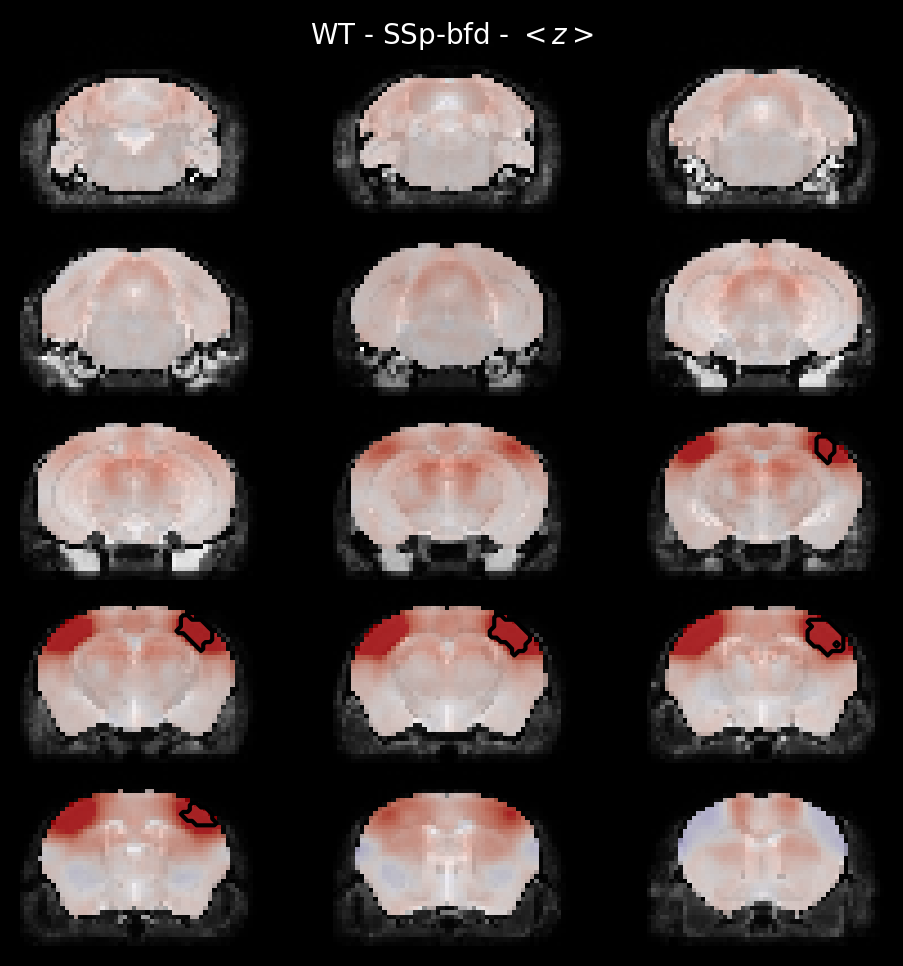

In [112]:
fig, _ = plot_img(
    effects['mean']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=np.linspace(10, 25, 15).astype(int),
    cmap=cc.cm['CET_D1'],
    vmin = -0.5,
    vmax = 0.5,
    th = 0.0
)

fig.suptitle(
    f'{group_tag} - {seed_acro} - $<z>$',
    color="white",
    fontsize=10
)

(<Figure size 3000x1000 with 1 Axes>,
 <Axes: >,
 array([18591, 19311, 19312, ..., 18330, 19067, 19066]))

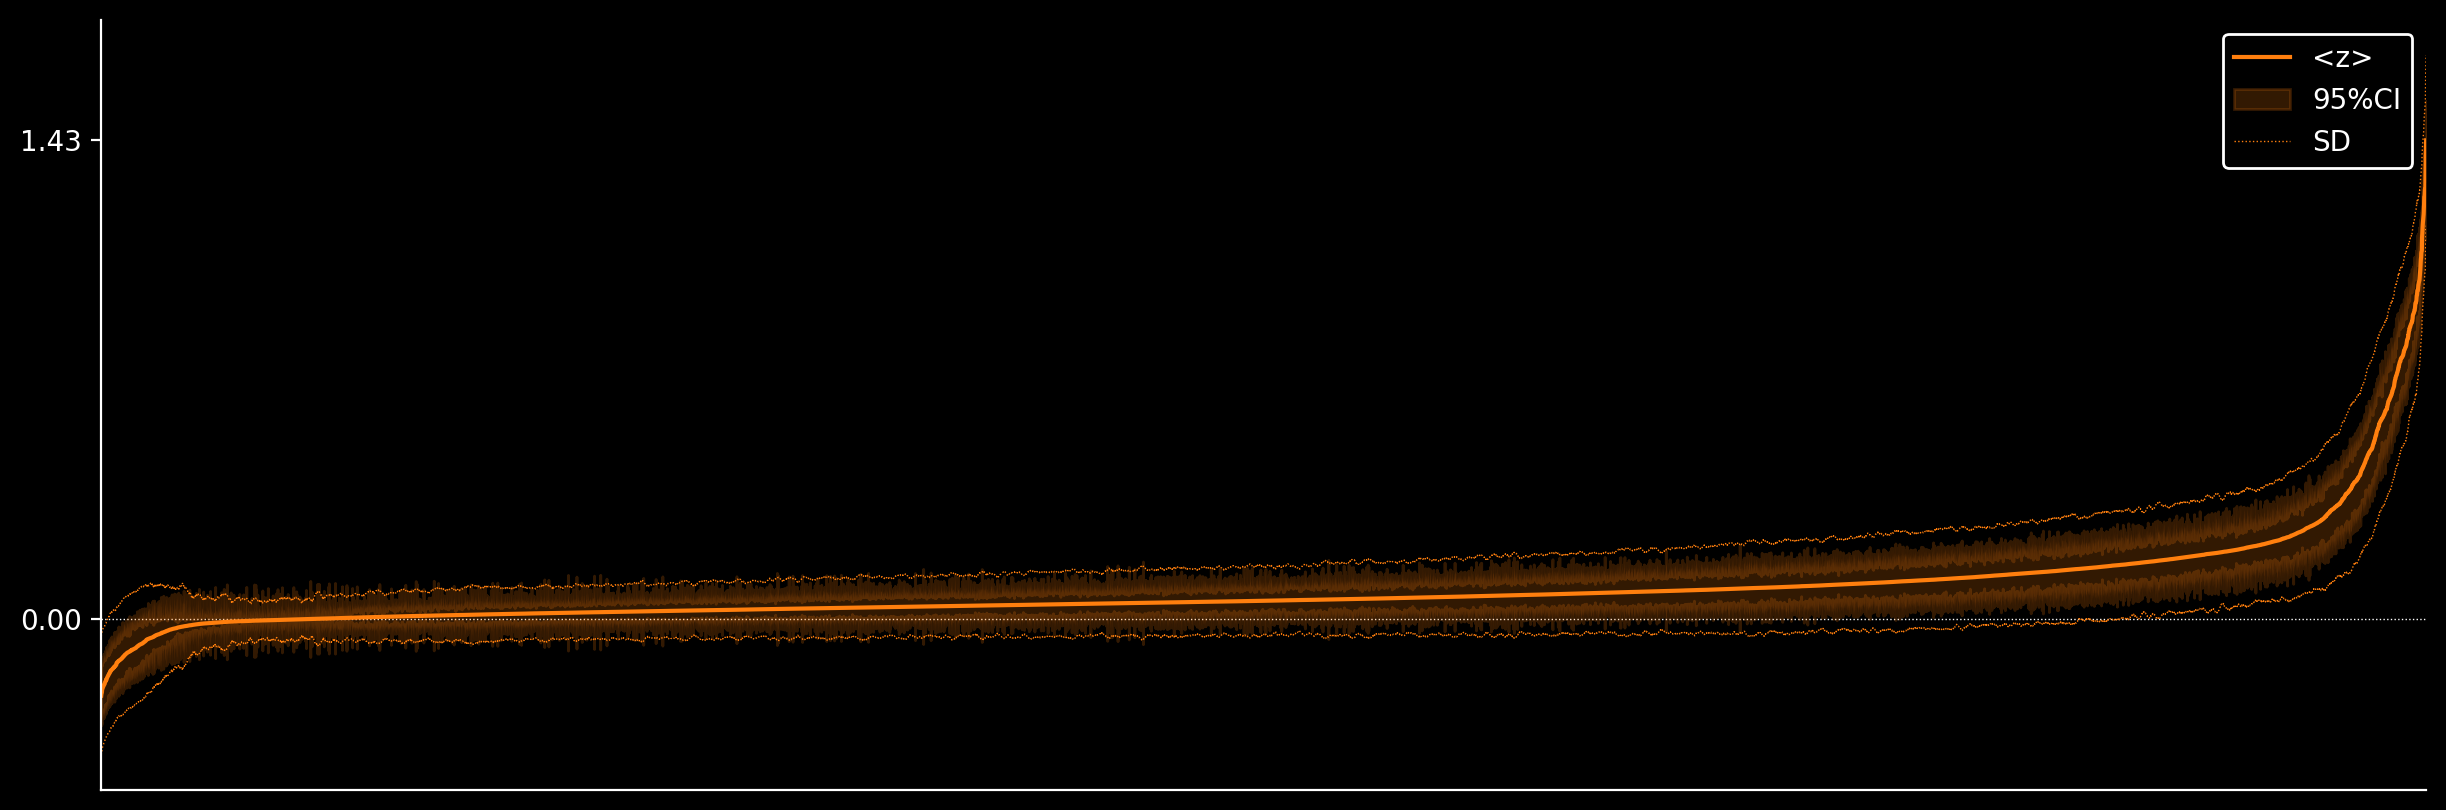

In [113]:
plot_cum_CI(
    effects['mean']['estimate'],
    effects['mean']['sd'],
    effects['mean']['ci'][:,1],
    effects['mean']['ci'][:,0],
    labels = ['<z>', '95%CI', 'SD']
)

Text(0.5, 0.98, 'WT - SSp-bfd - $\\hat{z}$')

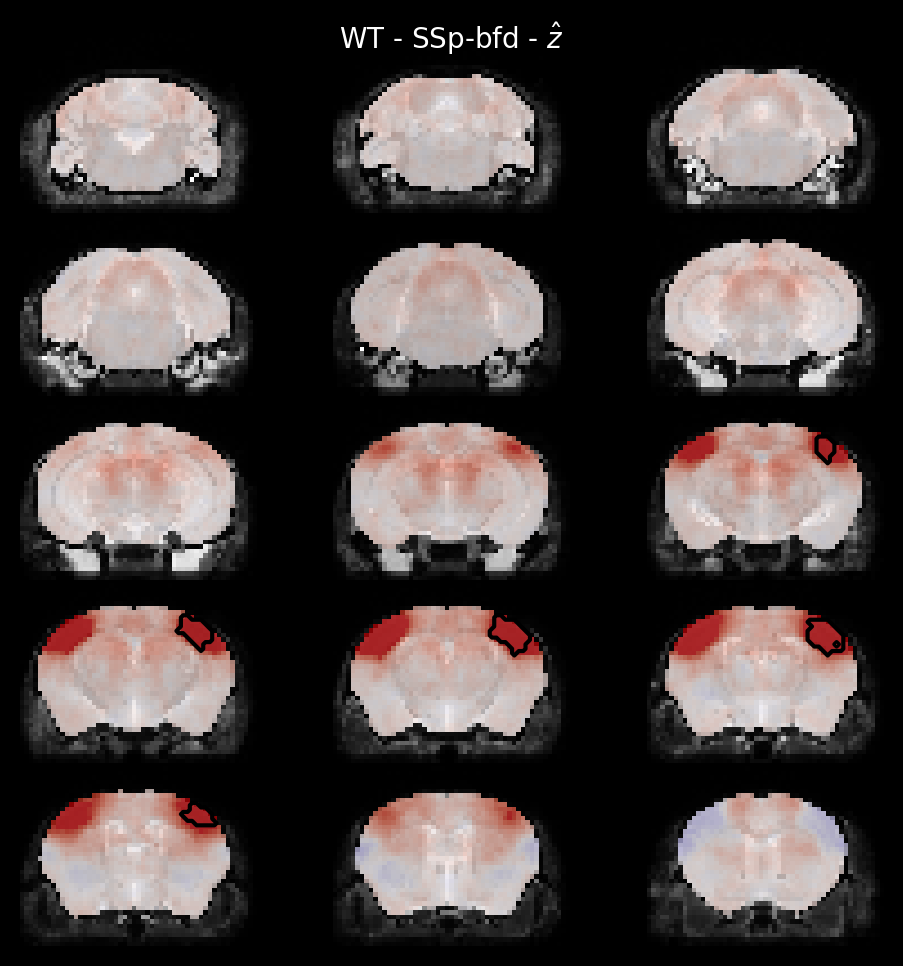

In [116]:
fig, _ = plot_img(
    effects['median']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=np.linspace(10, 25, 15).astype(int),
    cmap=cc.cm['CET_D1'],
    vmin = -0.5,
    vmax = 0.5,
    th = 0.0
)

fig.suptitle(
    f"{group_tag} - {seed_acro} - " r"$\hat{z}$",
    color="white",
    fontsize=10,
)

(<Figure size 3000x1000 with 1 Axes>,
 <Axes: >,
 array([19312, 19311, 18563, ..., 19067, 18330, 19066]))

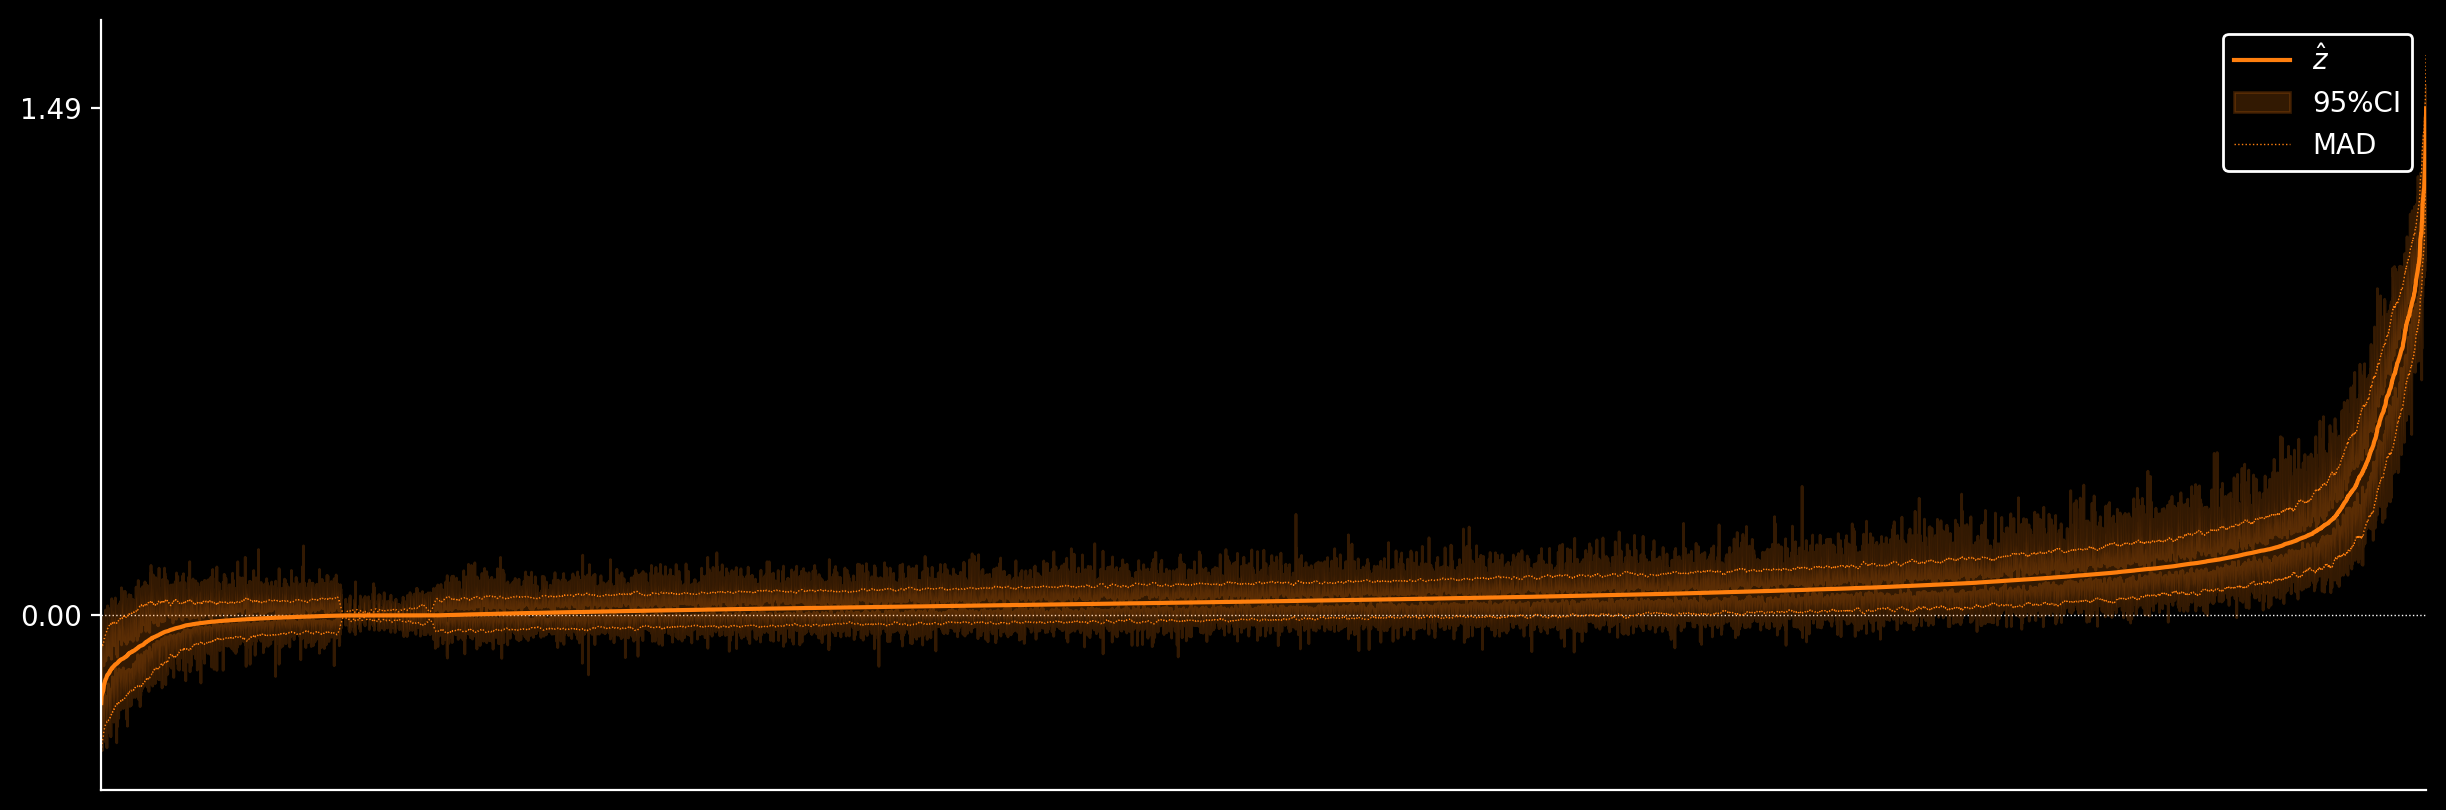

In [117]:
plot_cum_CI(
    effects['median']['estimate'],
    effects['median']['mad'],
    effects['median']['ci'][:,1],
    effects['median']['ci'][:,0],
    labels = ['$\hat{z}$', '95%CI', 'MAD']
)

Text(0.5, 0.98, 'WT - SSp-bfd - $d$')

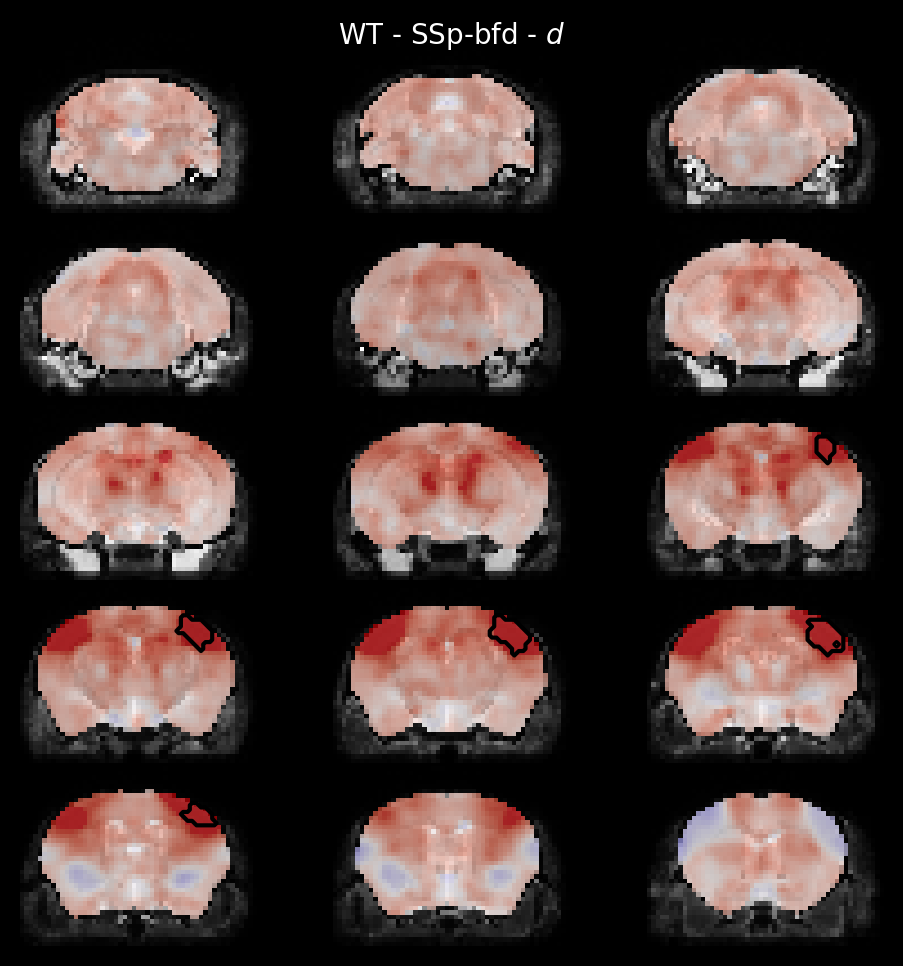

In [118]:
fig, _ = plot_img(
    effects['cohens_d']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=np.linspace(10, 25, 15).astype(int),
    cmap=cc.cm['CET_D1'],
    vmin = -2,
    vmax = 2.0,
    th = 0.0
)

fig.suptitle(
    f"{group_tag} - {seed_acro} - " r"$d$",
    color="white",
    fontsize=10,
)

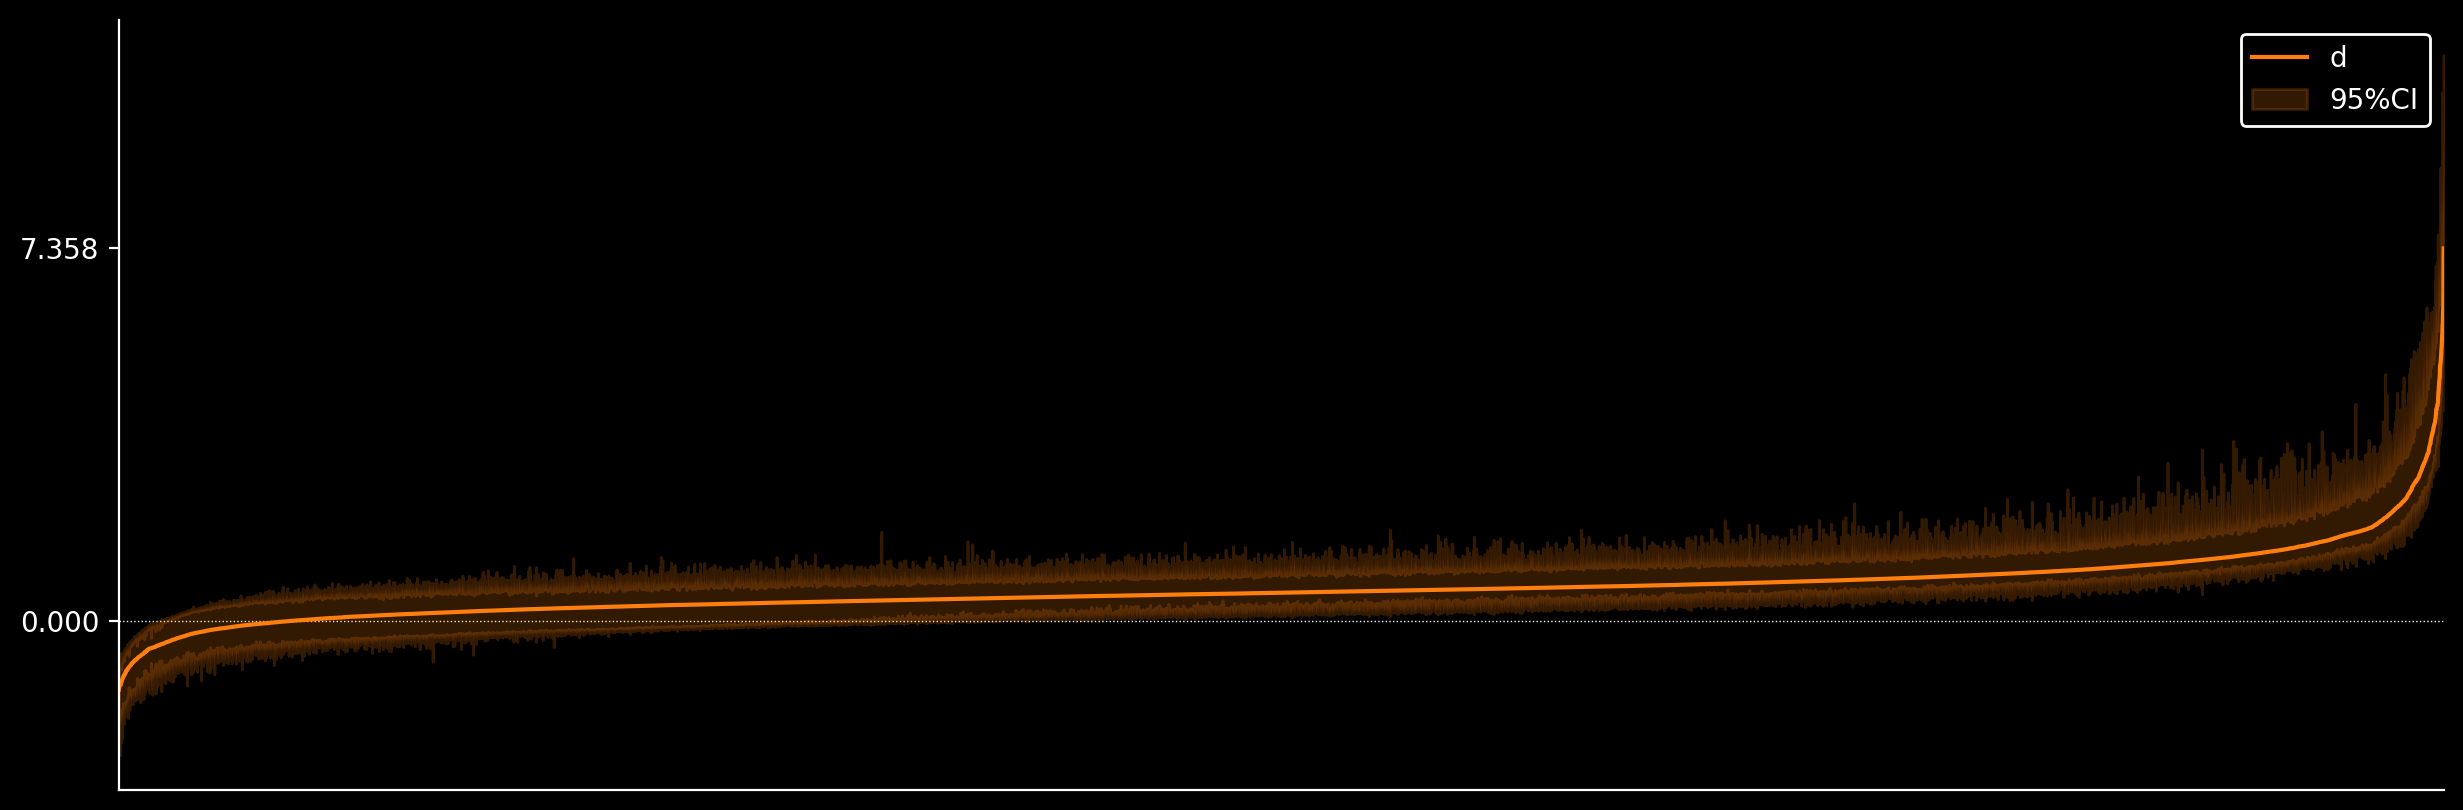

In [119]:
valid = np.isfinite(effects['cohens_d']["estimate"]) & np.isfinite(effects['cohens_d']['ci'][:,1]) & np.isfinite(effects['cohens_d']['ci'][:,0])

fig, ax, order = plot_cum_CI(
    vals=effects['cohens_d']["estimate"][valid],
    sd=None,
    cip=effects['cohens_d']['ci'][:,1][valid],
    cim=effects['cohens_d']['ci'][:,0][valid],
    labels=("d",'95%CI'),
)

## Compute and Correct stats

`compute_stats_one_sample()` computes the uncorrected voxelwise tests against zero stored in `stats`. `corect_maps_one_sample()` applies ultiple comparison to the results and stores it in `corrected`. Both dictionaries preserve the voxel order of `group_matrix`.

- `stats`

| Field	| stats["ttest"] | stats["wilcoxon"] |
| -------- | -------- | -------- |
| `statistic`	| Signed one-sample t-statistic. Positive means the group mean is above zero. |	Unsigned Wilcoxon $(W=\min(W_+,W_-))$. |
| `signed_statistic` |	—	| $(W_+-W_-)$. Positive means the positive observations carry more rank weight. |
| `pvalues`	| Raw two-sided t-test p-values.	| Raw two-sided Wilcoxon p-values. |
| `valid_voxels`	| Boolean mask of voxels with finite p-values. Constant and nonfinite columns are excluded. |	Boolean mask of voxels with finite p-values. All-zero and nonfinite columns are excluded. |


- `corrected`

| Dictionary path |	Contents |
| -------- | -------- |
| `corrected["ttest"]["bonferroni"]` and `corrected["ttest"]["fdr_bh"]`	| Adjusted p-values (pvalues_corrected), a Boolean significance mask (reject), and the number of included voxels (n_comparisons).|
| `corrected["wilcoxon"]["bonferroni"]` and `corrected["wilcoxon"]["fdr_bh"]`	| The same three fields, computed separately for the Wilcoxon test. |
| `corrected["ttest"]["fsl_cluster"]`	| reject marks voxels belonging to significant clusters. thresholded_z retains the signed group Z-statistic in those clusters and is 0.0 elsewhere.|

In [120]:
t0 = time()

stats = compute_stats_one_sample(group_matrix, tests=["ttest", "wilcoxon"])

corrected = correct_maps_one_sample(
    stats,
    methods=("bonferroni", "fdr_bh", "fsl_cluster"),
    cluster={
        "group_matrix": group_matrix,
        "mask_file": data_obj.brain_mask_file,
        "z_threshold": 2.1,
    },
)

print(f'\nEllapsed time: {time()-t0:.2f}s')

261124-09:14:22,528 nipype.interface INFO:
	 stdout 2026-11-24T09:14:22.527965:DLH 0.120848
261124-09:14:22,529 nipype.interface INFO:
	 stdout 2026-11-24T09:14:22.529559:VOLUME 21145
261124-09:14:22,529 nipype.interface INFO:
	 stdout 2026-11-24T09:14:22.529559:RESELS 39.4568
261124-09:14:22,530 nipype.interface INFO:
	 stdout 2026-11-24T09:14:22.529559:FWHMvoxel 4.22795 2.41143 3.87005
261124-09:14:22,530 nipype.interface INFO:
	 stdout 2026-11-24T09:14:22.529559:FWHMmm 0.992275 1.08514 0.908276
261124-09:14:23,88 nipype.interface INFO:
	 stdout 2026-11-24T09:14:23.088563:Cluster Index	Voxels	P	-log10(P)	MAX	MAX X (vox)	MAX Y (vox)	MAX Z (vox)	COG X (vox)	COG Y (vox)	COG Z (vox)
261124-09:14:23,90 nipype.interface INFO:
	 stdout 2026-11-24T09:14:23.088563:1	11233	1.16e-41	40.9	8.47	12	21	28	27	19.5	22.9
261124-09:14:23,636 nipype.interface INFO:
	 stdout 2026-11-24T09:14:23.636569:Cluster Index	Voxels	P	-log10(P)	MAX	MAX X (vox)	MAX Y (vox)	MAX Z (vox)	COG X (vox)	COG Y (vox)	COG Z (

### Unthresholded maps

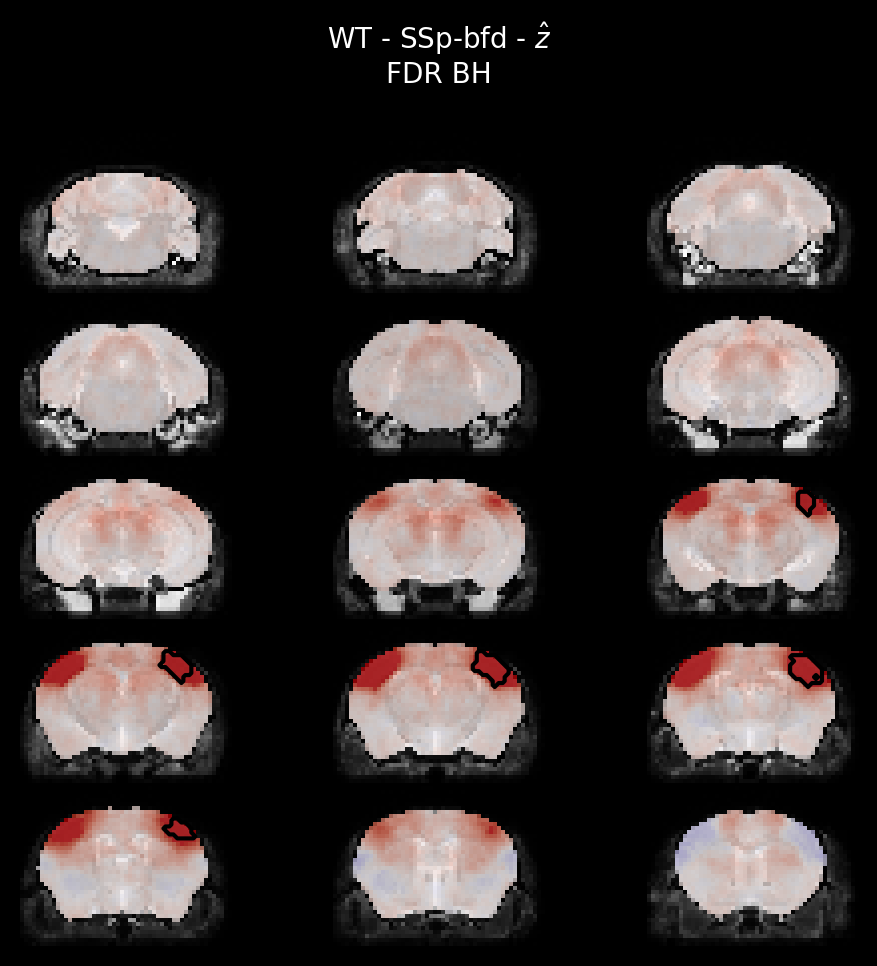

In [121]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    effects['median']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap=cc.cm['CET_D1'],
    vmin = -0.5,
    vmax = 0.5,
    th = 0,
)

fig.suptitle(
    f'{group_tag} - {seed_acro} - $\hat{{z}}$\nFDR BH',
    color="white",
    fontsize=10
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["wilcoxon"]["bonferroni"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

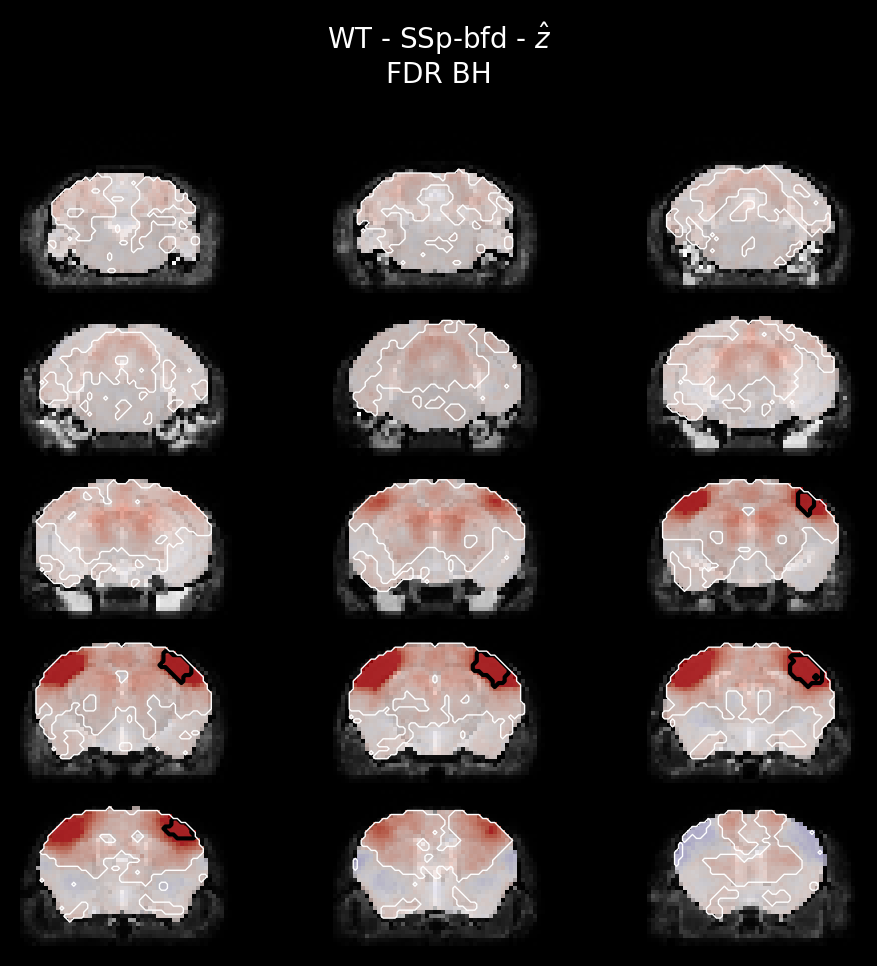

In [51]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    effects['median']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap=cc.cm['CET_D1'],
    vmin = -0.5,
    vmax = 0.5,
    th = 0,
)

fig.suptitle(
    f'{group_tag} - {seed_acro} - $\hat{{z}}$\nFDR BH',
    color="white",
    fontsize=10
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["wilcoxon"]["fdr_bh"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

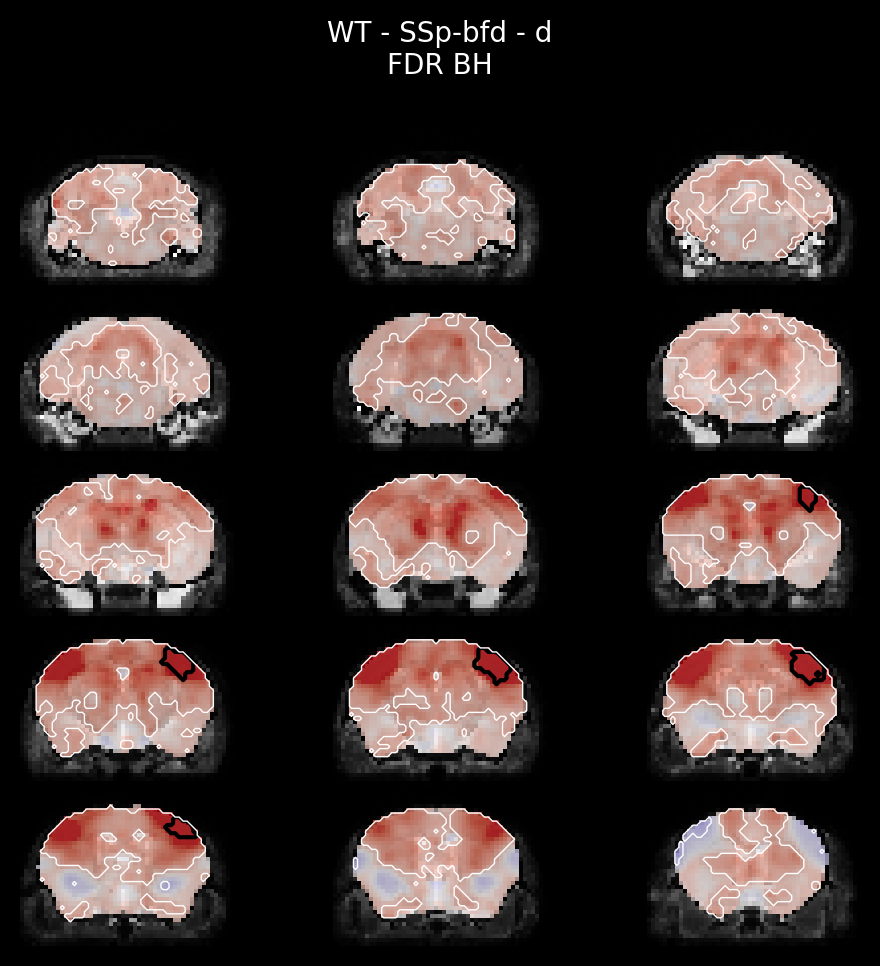

In [52]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    effects['cohens_d']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap=cc.cm['CET_D1'],
    vmin = -2,
    vmax = 2,
    th = 0,
)

fig.suptitle(
    f'{group_tag} - {seed_acro} - d\nFDR BH',
    color="white",
    fontsize=10
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["wilcoxon"]["fdr_bh"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

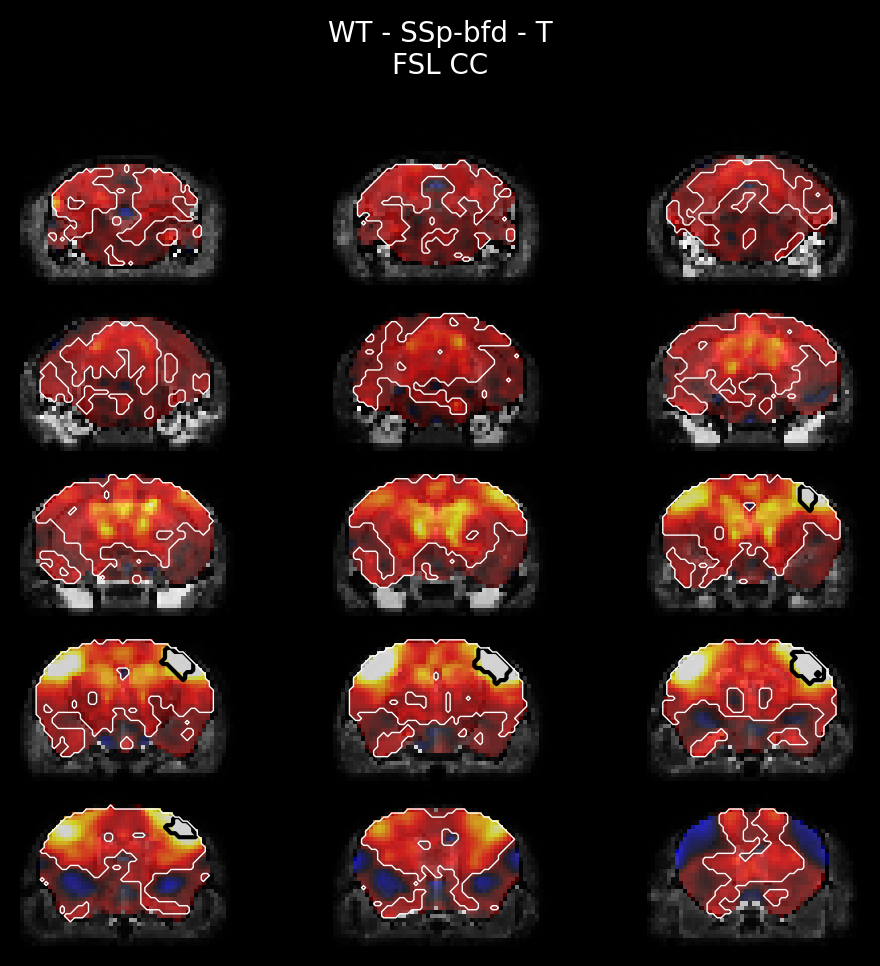

In [53]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    stats['ttest']['statistic'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap='cold_hot',
    vmin = -12,
    vmax = 12,
    th = 0,
)

fig.suptitle(
    f'{group_tag} - {seed_acro} - T\nFSL CC',
    color="white",
    fontsize=10
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["ttest"]["fsl_cluster"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

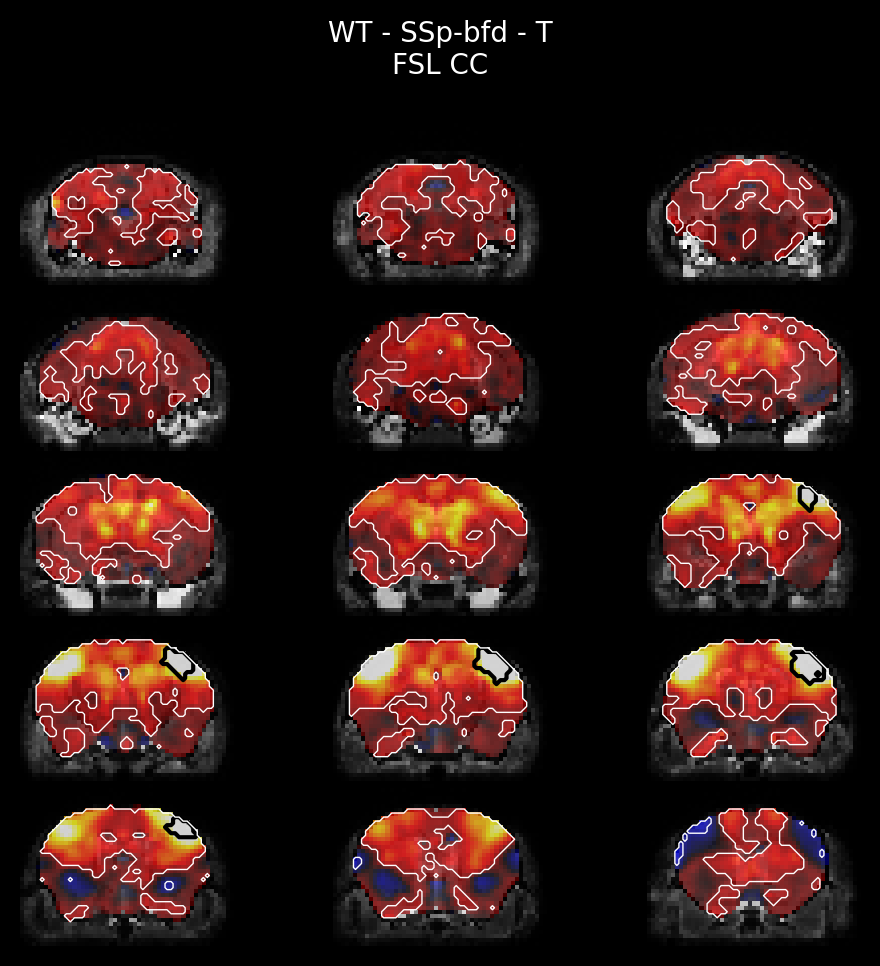

In [54]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    stats['ttest']['statistic'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap='cold_hot',
    vmin = -12,
    vmax = 12,
    th = 0,
)

fig.suptitle(
    f'{group_tag} - {seed_acro} - T\nFDR BH',
    color="white",
    fontsize=10
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["ttest"]["fdr_bh"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

### Threhsolded maps

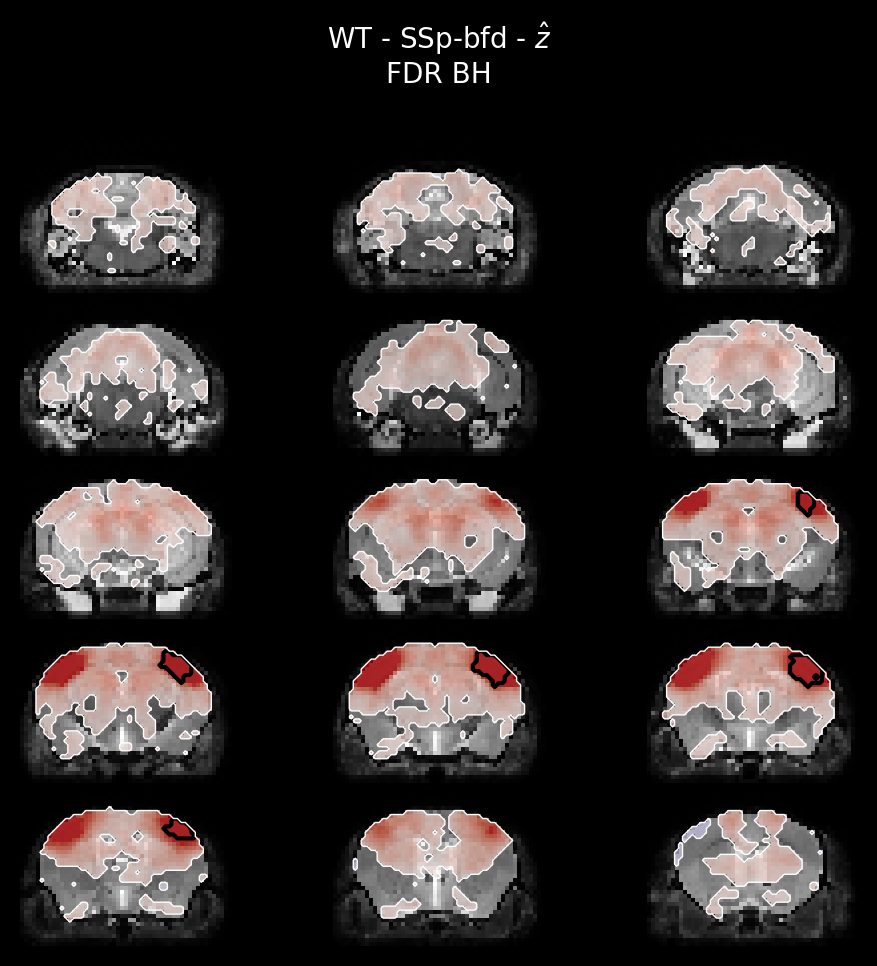

In [58]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    effects['median']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap=cc.cm['CET_D1'],
    vmin = -0.5,
    vmax = 0.5,
    th = (corrected["wilcoxon"]["fdr_bh"]["reject"]>0).astype(float),
)

fig.suptitle(
    f'{group_tag} - {seed_acro} - $\hat{{z}}$\nFDR BH',
    color="white",
    fontsize=10
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["wilcoxon"]["fdr_bh"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

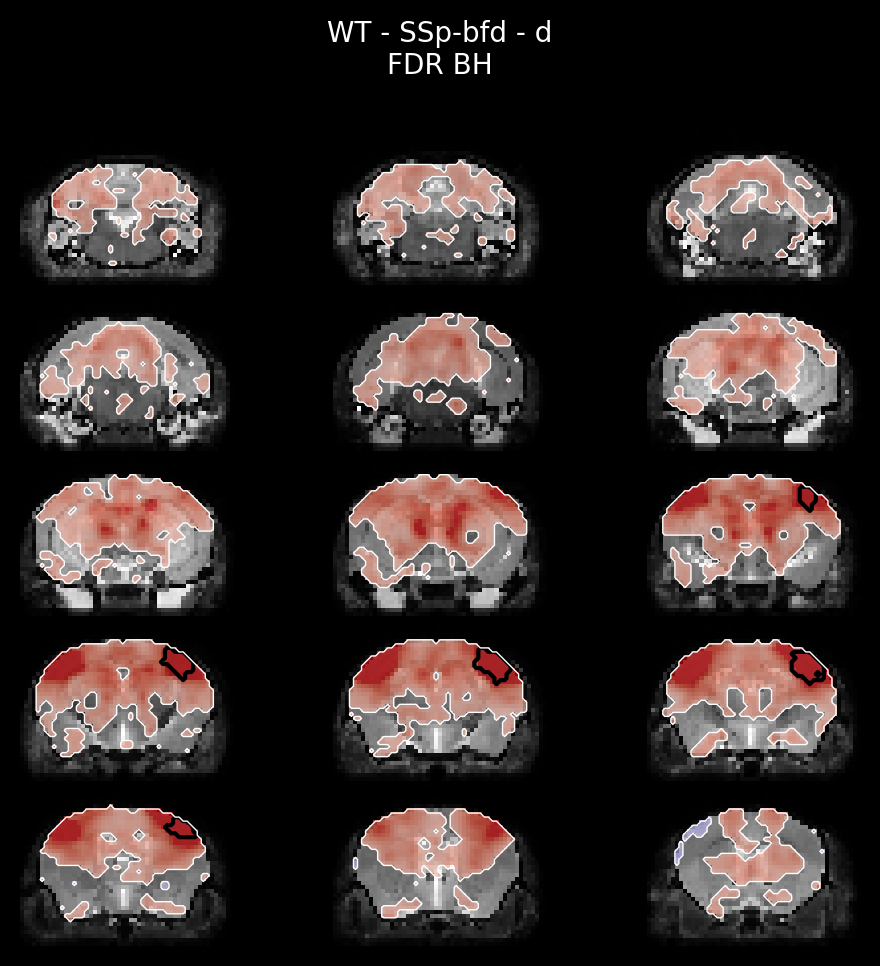

In [59]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    effects['cohens_d']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap=cc.cm['CET_D1'],
    vmin = -2,
    vmax = 2,
    th = (corrected["wilcoxon"]["fdr_bh"]["reject"]>0).astype(float),
)

fig.suptitle(
    f'{group_tag} - {seed_acro} - d\nFDR BH',
    color="white",
    fontsize=10
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["wilcoxon"]["fdr_bh"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

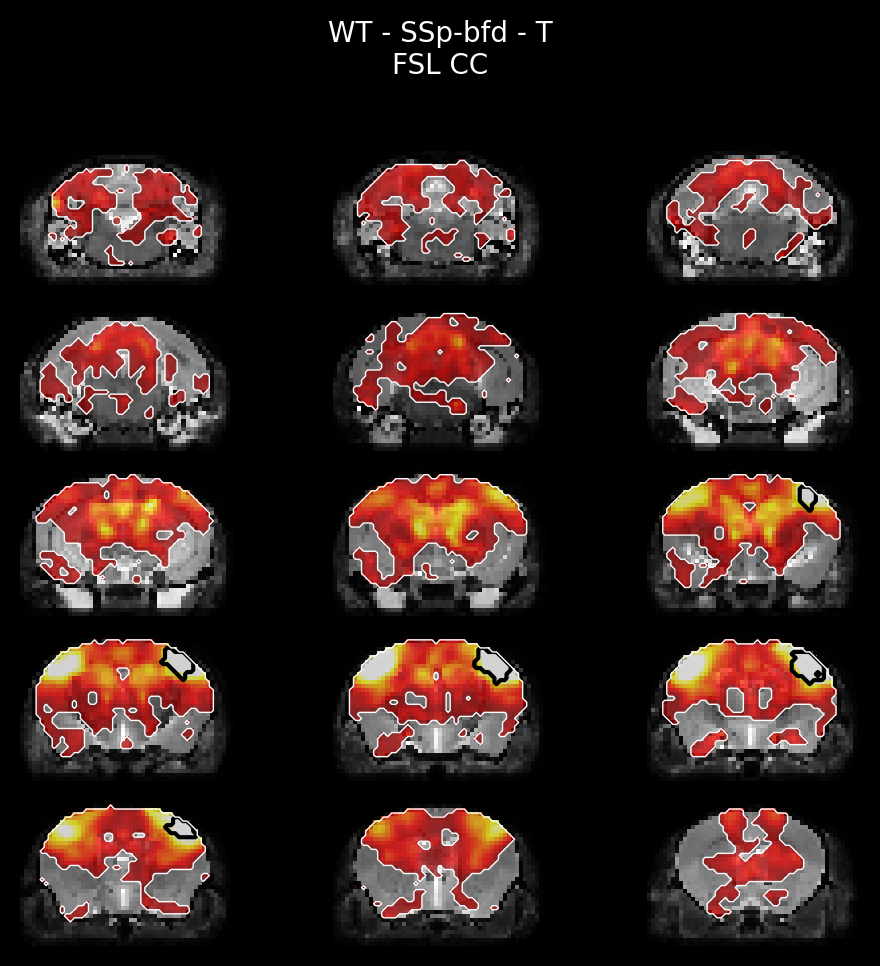

In [60]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    stats['ttest']['statistic'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap='cold_hot',
    vmin = -12,
    vmax = 12,
    th = (corrected["ttest"]["fsl_cluster"]["reject"]>0).astype(float),
)

fig.suptitle(
    f'{group_tag} - {seed_acro} - T\nFSL CC',
    color="white",
    fontsize=10
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["ttest"]["fsl_cluster"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

# Two Samples

In `rubella` `stats` module, two samples analysis is divided into three steps which match strictly the one sample implementation.
- `estimate_maps_two_samples` is independent and estimates typical metrics over SBMs differences for description of the SBM change distribution (effect estimate and typical deviation)
    - average, standard deviation of the mean, standard error of the mean, 95% confidence interval based on Student's law
    - median, standard error of the median and 95% confidence interval based on bootstraping
    - Cohen's d, standard error of the mean and 95% confidence interval based on bootstraping
- `compute_stats_two_samples` evaluates statistical results based on on two techniques
    - mass univariate `ttest` for parametric testing
    - mass univariate `mannwhitneyu` for non parametric testing
- `correct_maps_two_samples` corrects the statistical results depending on the statistics with
    - `bonferroni` correction
    - `fdr_bh` Benjamini Hochberg false discovery rate correction procesdure
    - `fsl_cluster` the cluster function of FSL

**N.B.**
- Median Absolute Deviation is not defined for the difference of two distributions

## Parameters

In [63]:
seed_acro = 'MOs'
factor = 'sex'
ref_tag = 'M'
group_tag = 'F'

seed_path = seed_df[seed_df['acro'] == seed_acro]['path'].item()

group_selector = (participants_df[factor] == group_tag)
group_matrix = np.array(SBMs[seed_acro])[group_selector,:]

ref_selector = (participants_df[factor] == ref_tag)
ref_matrix = np.array(SBMs[seed_acro])[ref_selector,:]

## Estimate maps

In [64]:
effects = estimate_maps_two_samples(
    group_matrix, 
    ref_matrix, 
    n_jobs=-2
)

Output()

Text(0.5, 0.98, 'MOs - sex: F - M $\\widehat{\\Delta z}$')

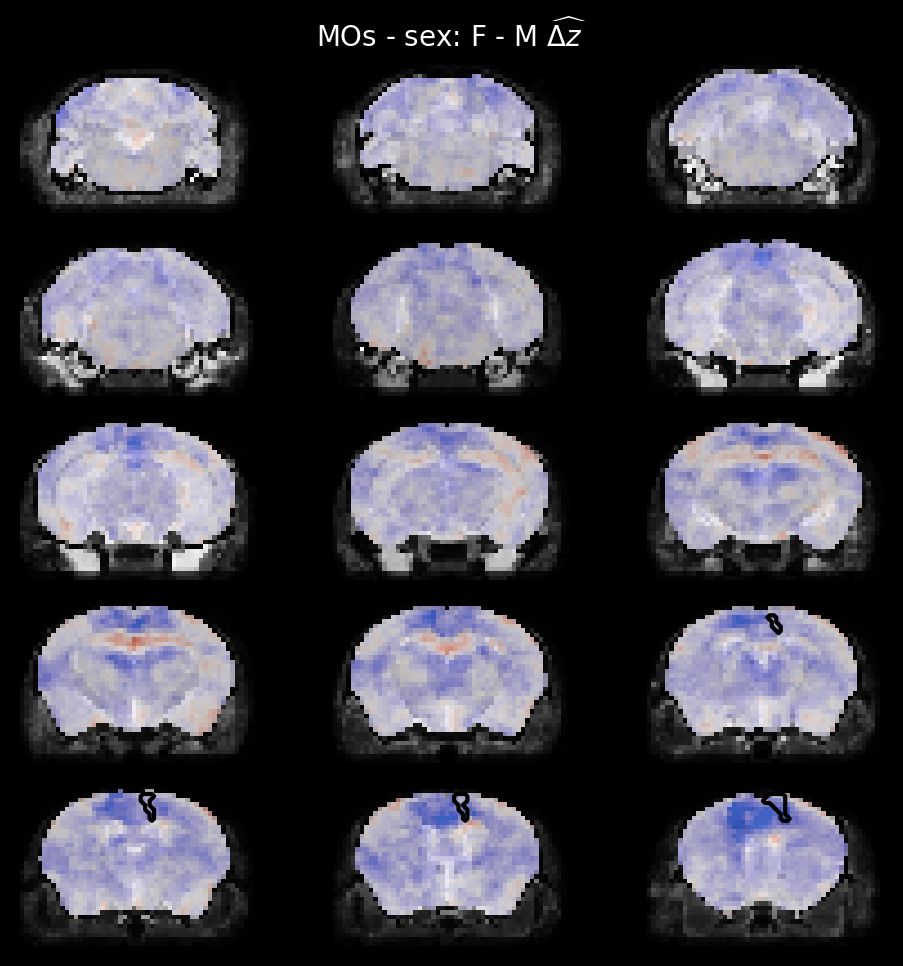

In [69]:
fig, _ = plot_img(
    effects['median']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=np.linspace(10, 25, 15).astype(int),
    cmap=cc.cm['CET_D1'],
    vmin = -0.25,
    vmax = 0.25,
    th = 0.0
)

fig.suptitle(
    f"{seed_acro} - {factor}: {group_tag} - {ref_tag} "
    r"$\widehat{\Delta z}$",
    color="white",
    fontsize=10,
)

(<Figure size 3000x1000 with 1 Axes>,
 <Axes: >,
 array([19921, 19279, 19944, ..., 17493, 16629, 17494]))

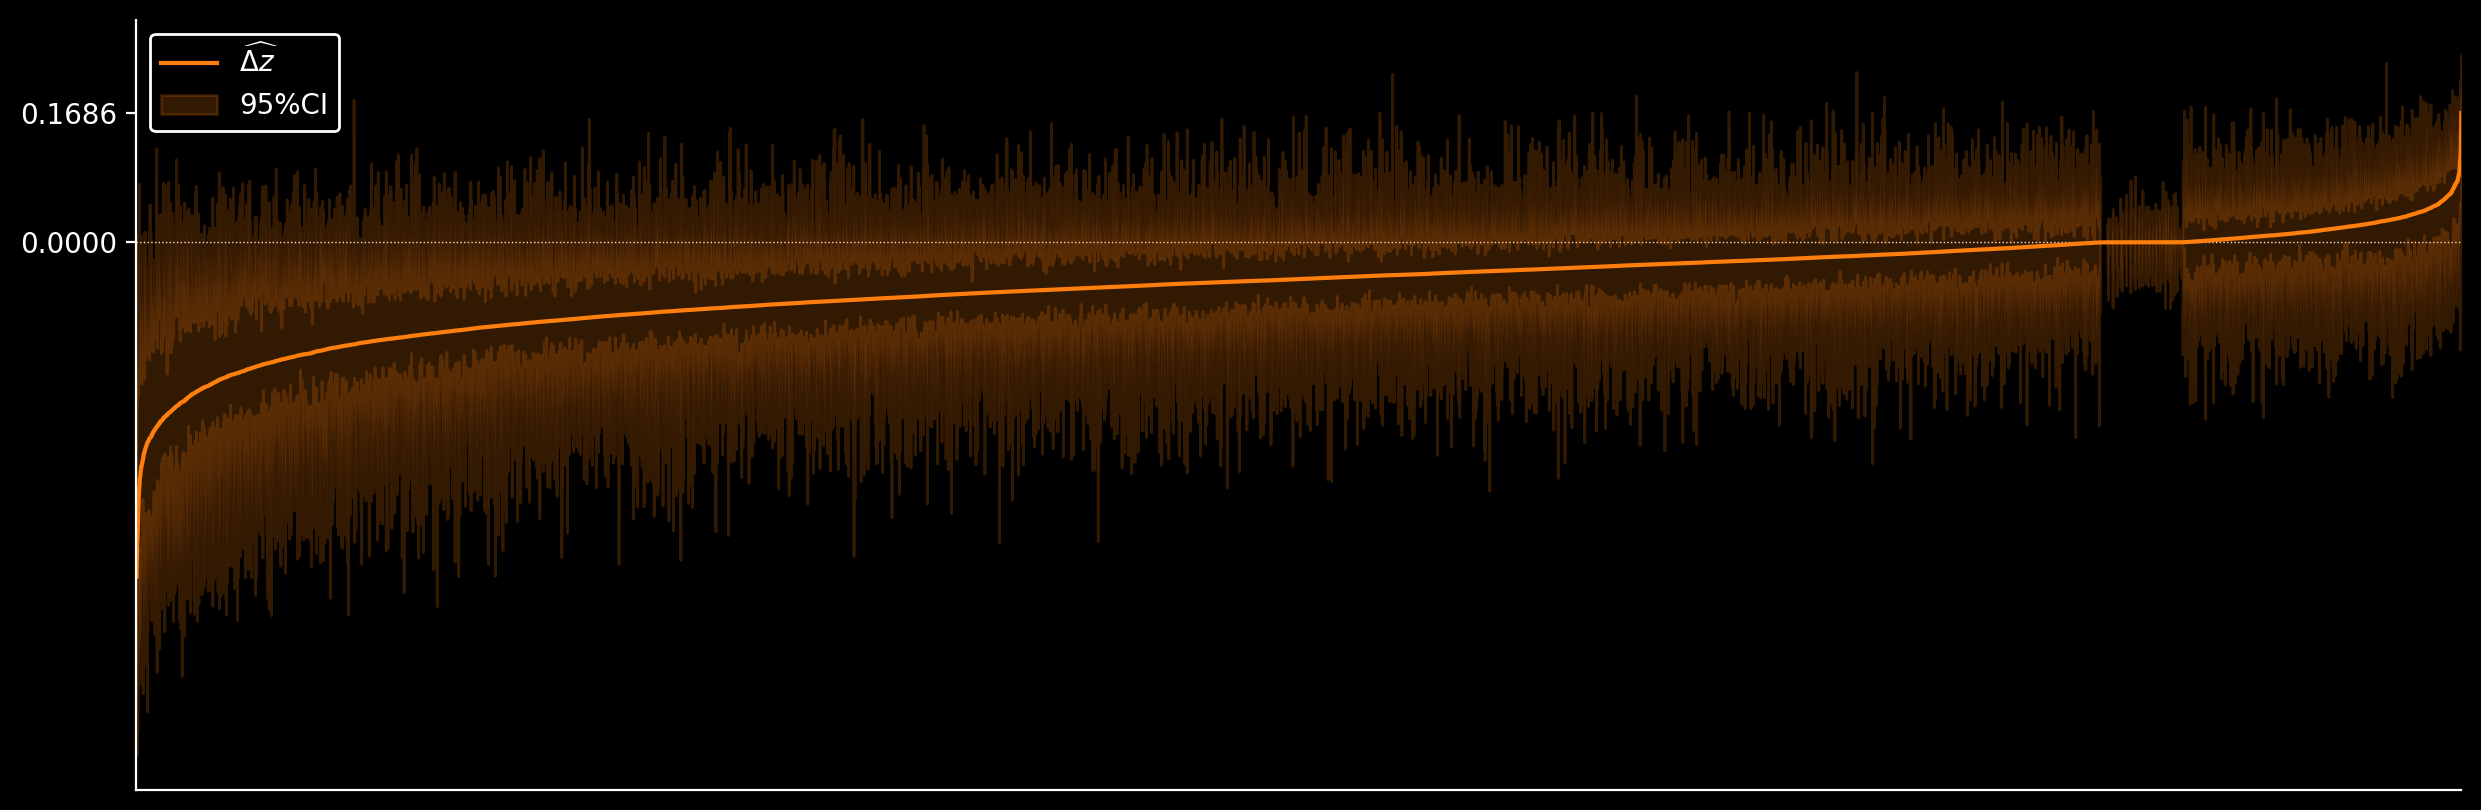

In [75]:
plot_cum_CI(
    effects['median']['estimate'],
    sd = None,
    cip = effects['median']['ci'][:,1],
    cim = effects['median']['ci'][:,0],
    labels = ['$\widehat{\Delta z}$', '95%CI']
)

Text(0.5, 0.98, 'MOs - sex: F - M $\\Delta d$')

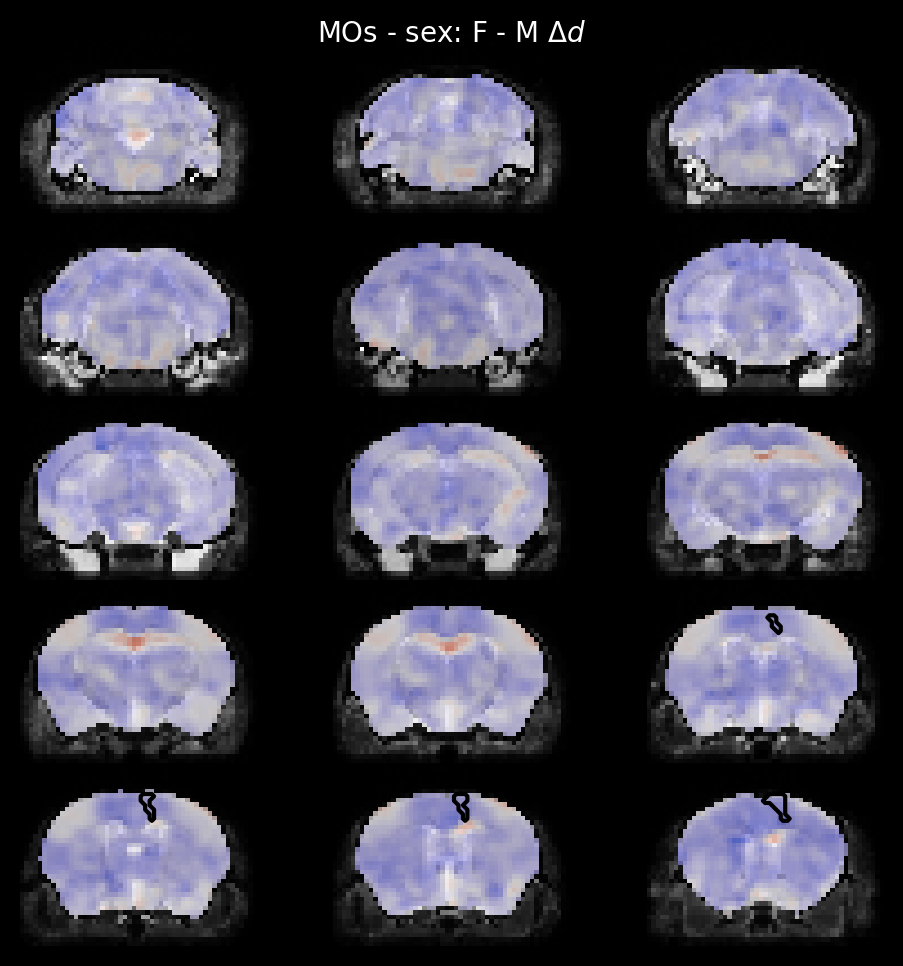

In [80]:
fig, _ = plot_img(
    effects['cohens_d']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=np.linspace(10, 25, 15).astype(int),
    cmap=cc.cm['CET_D1'],
    vmin = -2,
    vmax = 2,
    th = 0.0
)

fig.suptitle(
    f"{seed_acro} - {factor}: {group_tag} - {ref_tag} "
    r"$\Delta d$",
    color="white",
    fontsize=10,
)

(<Figure size 3000x1000 with 1 Axes>,
 <Axes: >,
 array([15818, 16706, 13805, ..., 17191, 16332, 16333]))

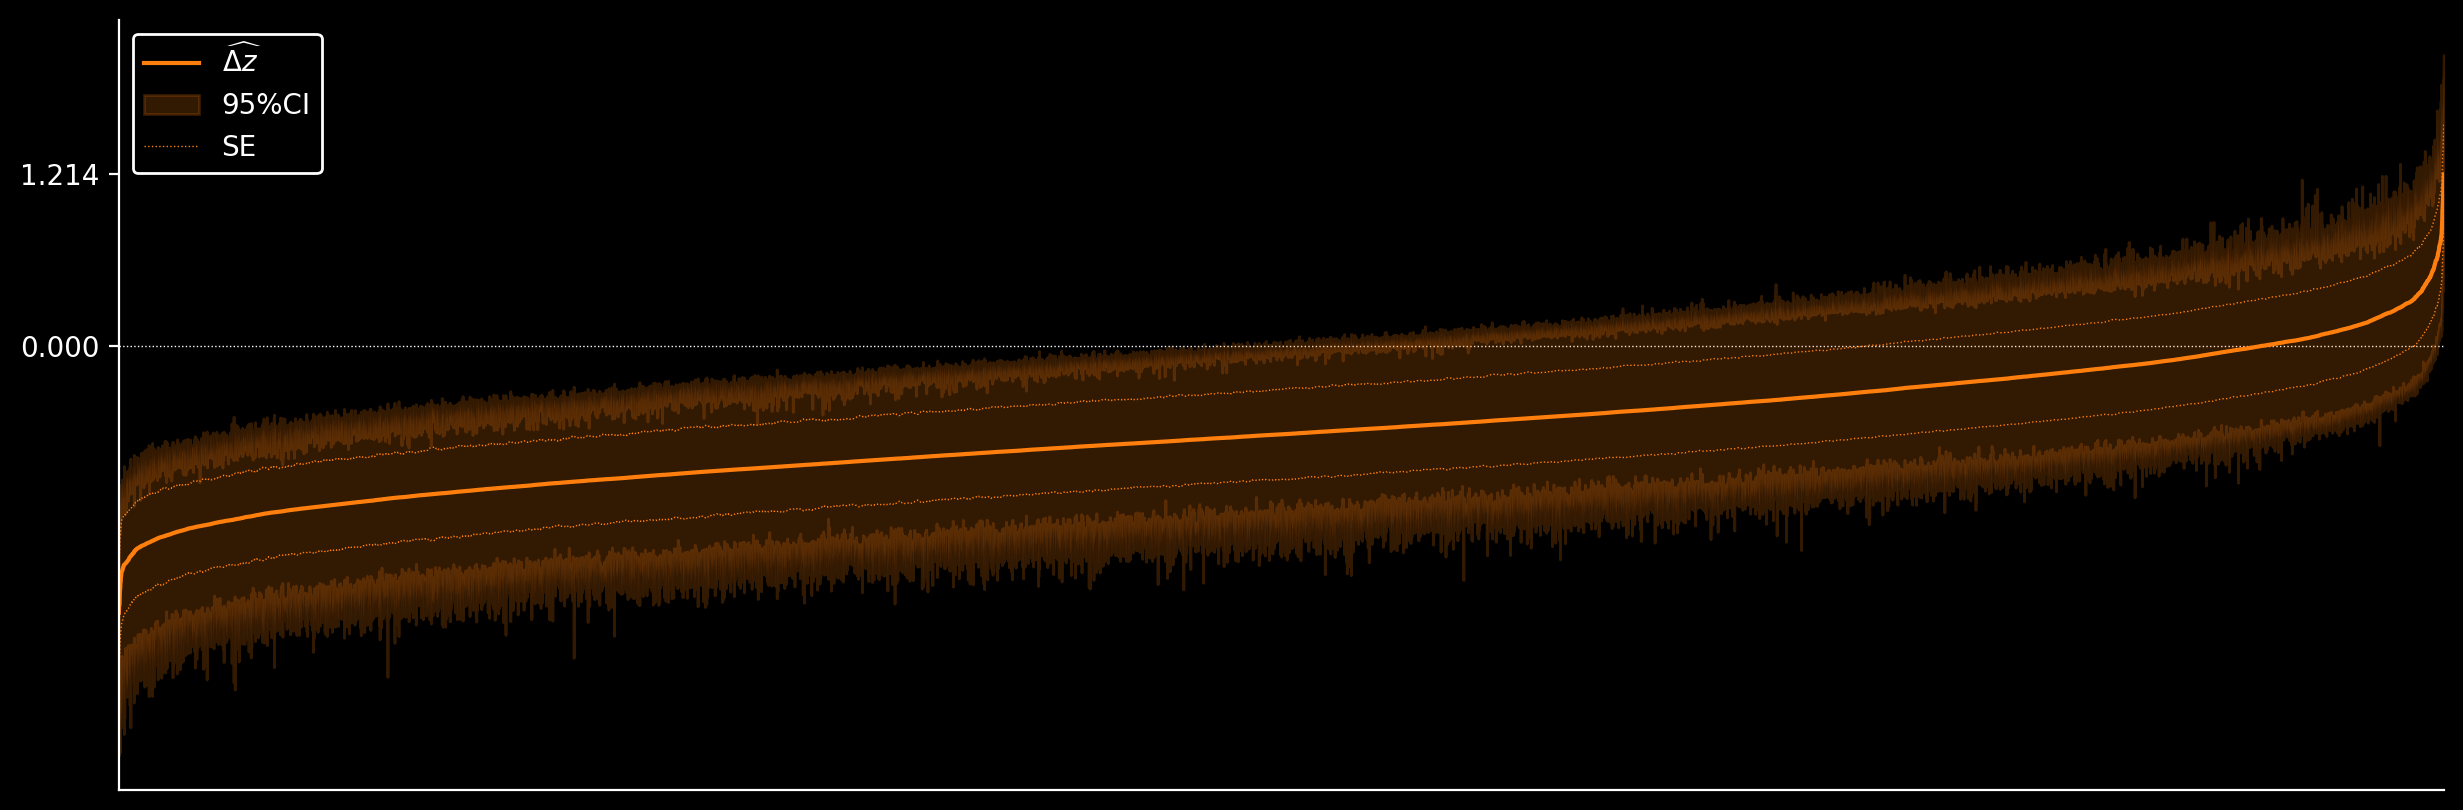

In [79]:
valid = np.isfinite(effects['cohens_d']["estimate"]) & np.isfinite(effects['cohens_d']['ci'][:,1]) & np.isfinite(effects['cohens_d']['ci'][:,0])

plot_cum_CI(
    effects['cohens_d']['estimate'][valid],
    sd = effects['cohens_d']['se'][valid],
    cip = effects['cohens_d']['ci'][valid,1],
    cim = effects['cohens_d']['ci'][valid,0],
    labels = ['$\widehat{\Delta z}$', '95%CI', 'SE']
)

## Compute and correct stats

In [82]:
t0 = time()

stats = compute_stats_two_samples(group_matrix, ref_matrix, n_jobs=3)

corrected = correct_maps_two_samples(
    stats,
    cluster={
        "group_matrix": group_matrix,
        "ref_matrix": ref_matrix,
        "mask_file": data_obj.brain_mask_file,
        "z_threshold": 3.1,
    },
)

print(f'\nEllapsed time: {time()-t0:.2f}s')

Output()

261124-08:23:30,197 nipype.interface INFO:
	 stdout 2026-11-24T08:23:30.197842:DLH 0.183861
261124-08:23:30,199 nipype.interface INFO:
	 stdout 2026-11-24T08:23:30.197842:VOLUME 21145
261124-08:23:30,199 nipype.interface INFO:
	 stdout 2026-11-24T08:23:30.197842:RESELS 25.3388
261124-08:23:30,200 nipype.interface INFO:
	 stdout 2026-11-24T08:23:30.197842:FWHMvoxel 3.78586 1.96312 3.40938
261124-08:23:30,200 nipype.interface INFO:
	 stdout 2026-11-24T08:23:30.197842:FWHMmm 0.888519 0.883403 0.800161
261124-08:23:30,590 nipype.interface INFO:
	 stdout 2026-11-24T08:23:30.590569:Cluster Index	Voxels	P	-log10(P)	MAX	MAX X (vox)	MAX Y (vox)	MAX Z (vox)	COG X (vox)	COG Y (vox)	COG Z (vox)
261124-08:23:30,984 nipype.interface INFO:
	 stdout 2026-11-24T08:23:30.984659:Cluster Index	Voxels	P	-log10(P)	MAX	MAX X (vox)	MAX Y (vox)	MAX Z (vox)	COG X (vox)	COG Y (vox)	COG Z (vox)
261124-08:23:30,986 nipype.interface INFO:
	 stdout 2026-11-24T08:23:30.984659:1	2651	0	48.1	5	27	30	25	28.7	21.5	24.3



### Unthresholded maps

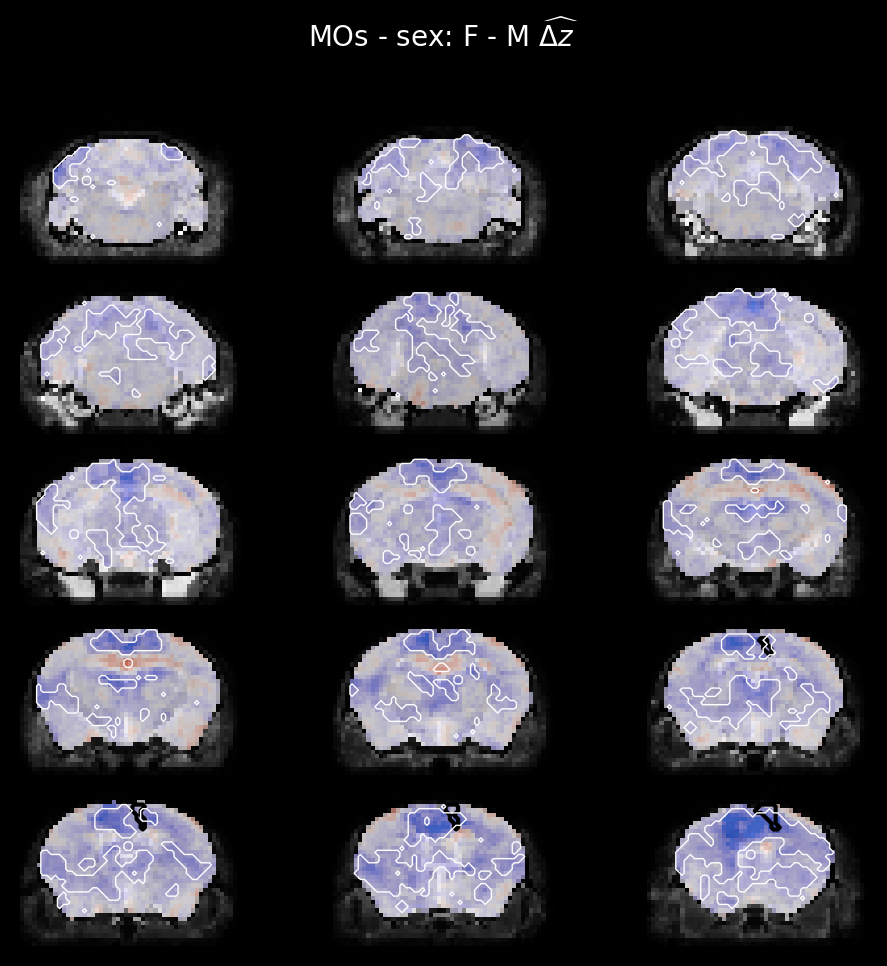

In [83]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    effects['median']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap=cc.cm['CET_D1'],
    vmin = -0.25,
    vmax = 0.25,
    th = 0,
)

fig.suptitle(
    f"{seed_acro} - {factor}: {group_tag} - {ref_tag} "
    r"$\widehat{\Delta z}$",
    color="white",
    fontsize=10,
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["mannwhitneyu"]["fdr_bh"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

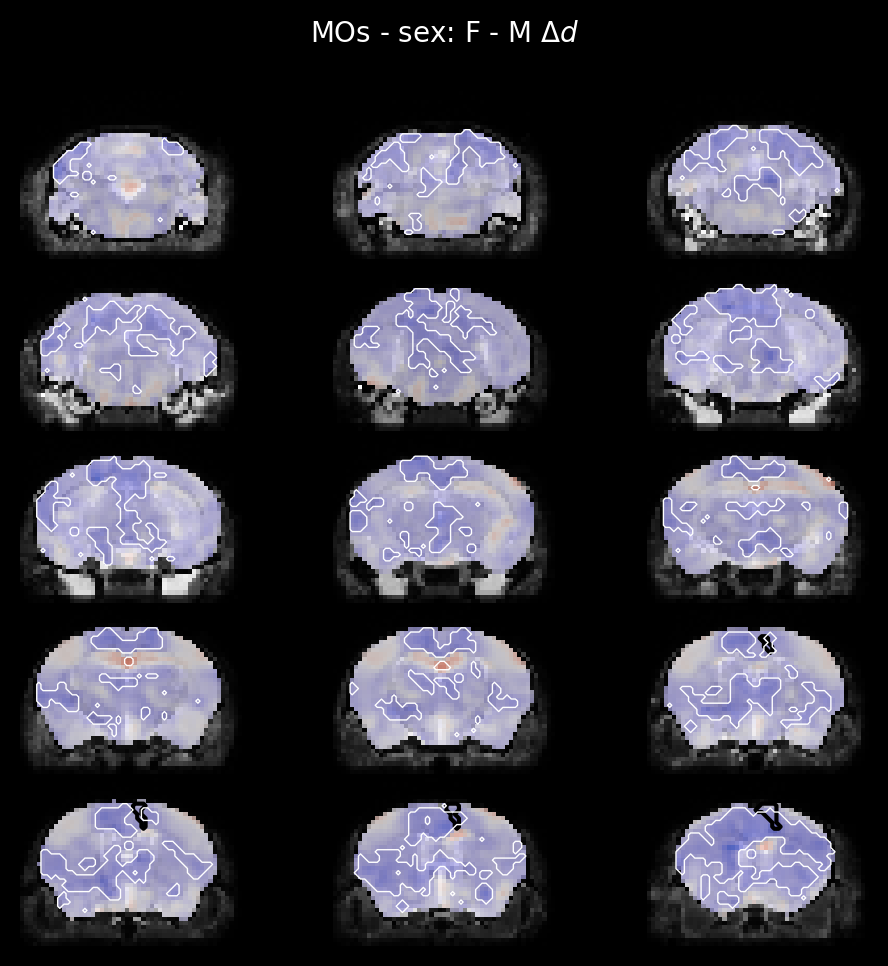

In [84]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    effects['cohens_d']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap=cc.cm['CET_D1'],
    vmin = -2,
    vmax = 2,
    th = 0,
)

fig.suptitle(
    f"{seed_acro} - {factor}: {group_tag} - {ref_tag} "
    r"$\Delta d$",
    color="white",
    fontsize=10,
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["mannwhitneyu"]["fdr_bh"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

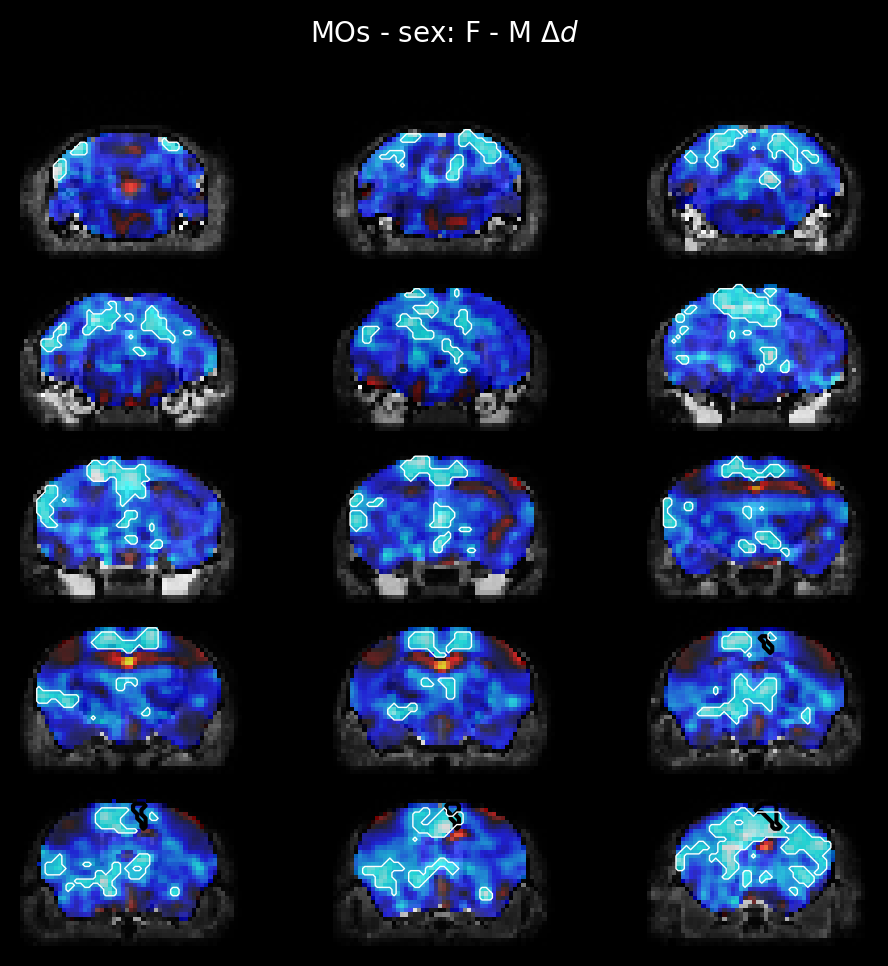

In [88]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    stats['pooled_ttest']['statistic'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap='cold_hot',
    vmin = -5,
    vmax = 5,
    th = 0,
)

fig.suptitle(
    f"{seed_acro} - {factor}: {group_tag} - {ref_tag} "
    r"$\Delta d$",
    color="white",
    fontsize=10,
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["pooled_ttest"]["fsl_cluster"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

### Thresholded

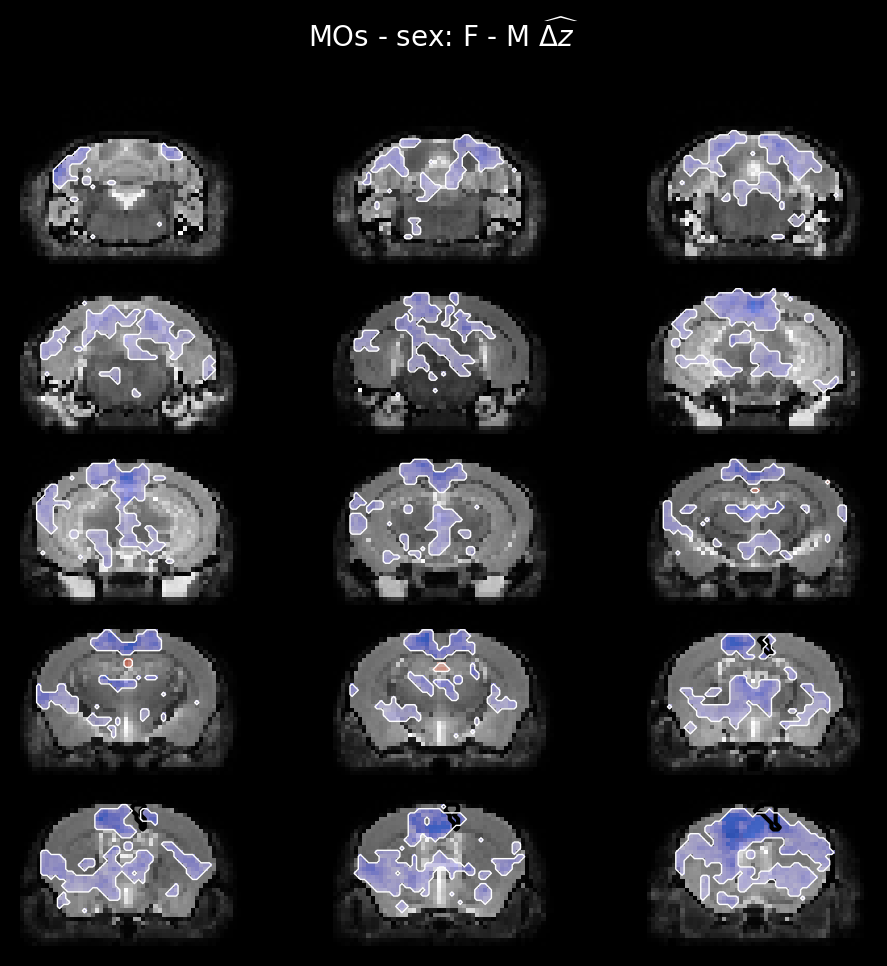

In [89]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    effects['median']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap=cc.cm['CET_D1'],
    vmin = -0.25,
    vmax = 0.25,
    th = (corrected["mannwhitneyu"]["fdr_bh"]["reject"]>0).astype(float),
)

fig.suptitle(
    f"{seed_acro} - {factor}: {group_tag} - {ref_tag} "
    r"$\widehat{\Delta z}$",
    color="white",
    fontsize=10,
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["mannwhitneyu"]["fdr_bh"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

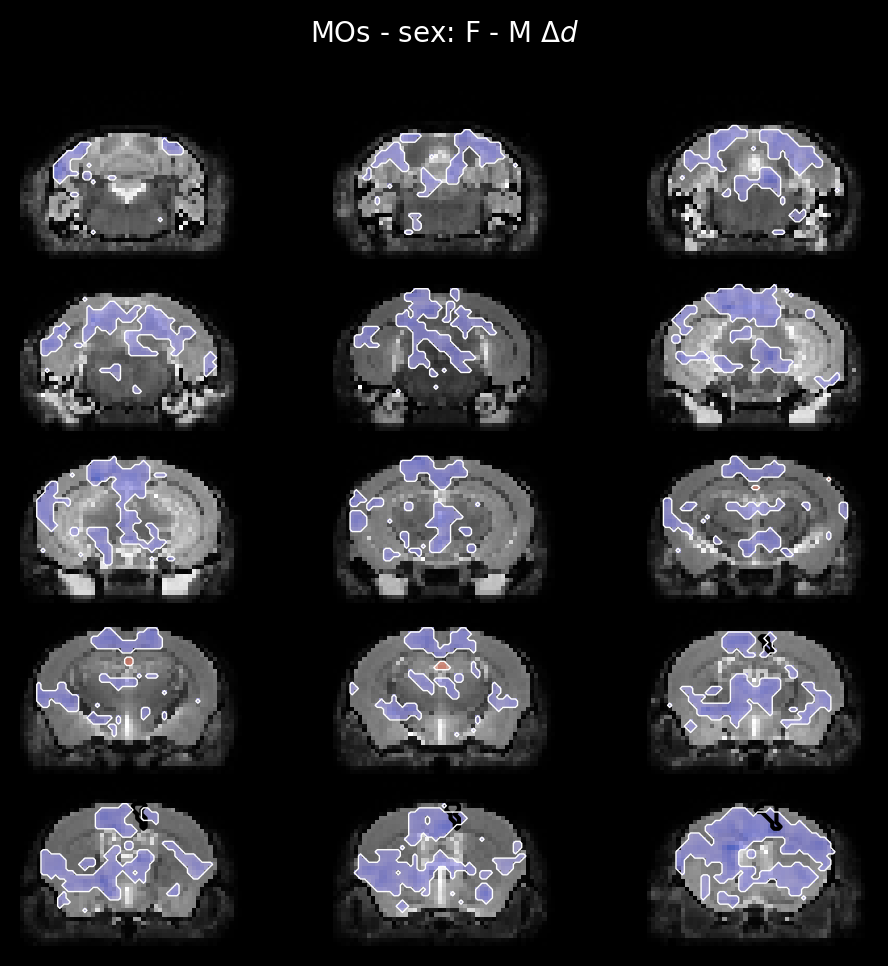

In [90]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    effects['cohens_d']['estimate'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap=cc.cm['CET_D1'],
    vmin = -2,
    vmax = 2,
    th = (corrected["mannwhitneyu"]["fdr_bh"]["reject"]>0).astype(float),
)

fig.suptitle(
    f"{seed_acro} - {factor}: {group_tag} - {ref_tag} "
    r"$\Delta d$",
    color="white",
    fontsize=10,
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["mannwhitneyu"]["fdr_bh"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

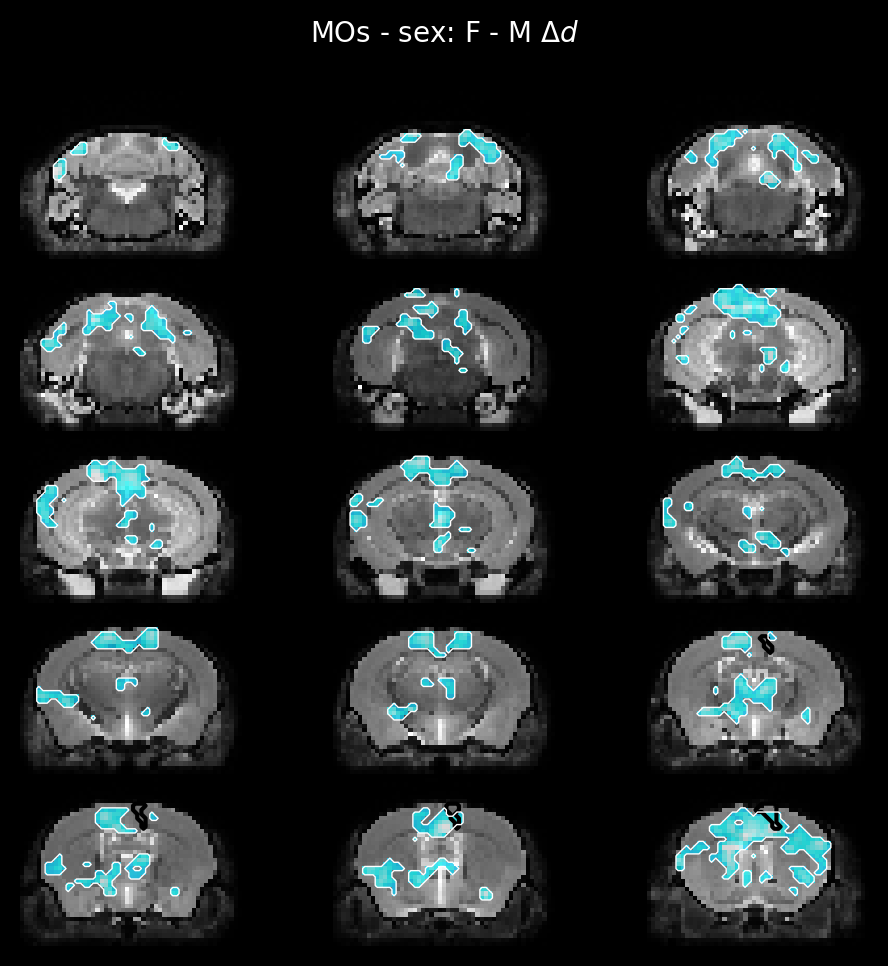

In [91]:
slice_ids=np.linspace(10, 25, 15).astype(int)

fig, ax = plot_img(
    stats['pooled_ttest']['statistic'],
    data_obj.brain_mask_file,
    template_path=str(template_path),
    seed_path=str(seed_path),
    slice_ids=slice_ids,
    cmap='cold_hot',
    vmin = -5,
    vmax = 5,
    th = (corrected["pooled_ttest"]["fsl_cluster"]["reject"]>0).astype(float),
)

fig.suptitle(
    f"{seed_acro} - {factor}: {group_tag} - {ref_tag} "
    r"$\Delta d$",
    color="white",
    fontsize=10,
)

plt.tight_layout()

p_img = sitk.GetArrayFromImage(recover_3D(mask_path, (corrected["pooled_ttest"]["fsl_cluster"]["reject"]>0).astype(float)))

for slice_id, axi in zip(slice_ids, ax.flatten()):

    img_2_display = np.rot90((p_img[:,slice_id,:]>0.5),2).astype(float)
    axi.contour(img_2_display, levels = [0.5], colors = ['w'], linewidths = [0.5])

# Linear Mixe Model - 2 factor designs

`compute_stats_factorial()` fits a separate two-by-two factorial model at each voxel for the connectivity maps in `SBMs[seed_acro]`. The call shown uses **ordinary least squares (OLS)** because it omits `random_groups`. The function fits a random-intercept mixed model when you supply grouping labels, such as a mouse ID for repeated scans.

- **The four effect maps**

Each entry is a dictionary. The two main-effect keys use the column names passed as `factor1` and `factor2`. For example, with `factor1="genotype"`, `factor2="sex"`, `factor1_order=["Het", "WT"]`, and `factor2_order=["F", "M"]`, the output has these keys:

| Key | What `estimate` measures at each voxel |
| --- | --- |
| `intercept` | The equally weighted average of the four fitted cell means (Het–F, Het–M, WT–F, WT–M). Included because `return_intercept=True`. |
| `genotype` | Het − WT, averaged equally over F and M. |
| `sex` | F − M, averaged equally over Het and WT. |
| `interaction` | (Het − WT in F) − (Het − WT in M). A positive value means the Het − WT contrast is more positive in F. |

The order arguments set the direction as **first level minus second level**. If an order is omitted, its observed string levels are sorted alphabetically, or in ascending order for numeric levels. Each cell contributes equally to the intercept, so with unequal cell sizes it can differ from the raw average across mice.

- **Fields in each entry**

| Field | Contents |
| --- | --- |
| `estimate` | Signed model coefficient, in the input map units. For Fisher-z connectivity input, the coefficient is in Fisher-z units. |
| `se` | Standard error of the coefficient. |
| `statistic` | The coefficient divided by its standard error. For this OLS call, it is a t-statistic with `n_observations - 4` residual degrees of freedom. With `random_groups`, it is a Wald z-statistic. |
| `pvalues` | Raw two-sided p-values for testing whether the coefficient equals zero. |
| `valid_voxels` | Boolean mask indicating where both the statistic and p-value are finite. |

Each field is a NumPy array of shape `(n_voxels,)` in the same voxel order as `SBMs[seed_acro]`. Voxels skipped by the fit have `NaN` in the numeric fields and `False` in `valid_voxels`.

- **Parallelisation and progress**

| Fitting mode | How the work is scheduled |
| --- | --- |
| **OLS** (current example) | NumPy fits a block of voxels at once, using the same design matrix for all voxels. With `show_progress=True`, the function processes blocks of up to `chunk_size` voxels sequentially. The default is 32. The OLS branch does not launch Joblib workers, so `n_jobs=-2` has no effect here. With progress disabled, it processes all eligible voxels in one vectorised block. |
| **Mixed model** (with `random_groups`) | Joblib schedules chunks of voxels concurrently, preferring process workers. Each worker fits one model per voxel within its chunk. `n_jobs=-2` requests one fewer worker than the available CPUs detected by Joblib. Completed chunks are written back to their original voxel indices. |

The Rich bar advances by the number of eligible voxels in each completed chunk. An attempted fit counts toward progress even if it fails, so 100% means all eligible voxels were processed. Use `valid_voxels` to see which fits yielded usable statistics.

- **Multiple-comparison correction**

```python
corrected = correct_maps_two_samples(
    lmm_effects,
    methods=("fdr_bh", "bonferroni"),
    alpha=0.05,
)
```

Each method is applied **across valid voxels within one model term**. With `return_intercept=True`, this gives four separate correction families for the seed: intercept, genotype, sex, and interaction. The call does not pool tests across terms or seeds.

| Method | What it controls at `alpha=0.05` |
| --- | --- |
| `fdr_bh` | Benjamini–Hochberg targets a 5% expected proportion of false discoveries among rejected voxels, under independence or suitable positive dependence. |
| `bonferroni` | Bonferroni controls the probability of one or more false rejections within a term's voxel family at 5%. |

Each `corrected[term][method]` entry contains:

| Field | Contents |
| --- | --- |
| `pvalues_corrected` | Adjusted p-values in the original voxel order. Excluded voxels have `NaN`. |
| `reject` | Boolean significance mask at the specified alpha. Excluded voxels are `False`. |
| `n_comparisons` | Number of valid voxelwise p-values included for that term. |

## Extract maps for plotting

```python
intercept_map = lmm_effects["intercept"]["estimate"]
genotype_map = lmm_effects["genotype"]["estimate"]
sex_map = lmm_effects["sex"]["estimate"]
interaction_map = lmm_effects["interaction"]["estimate"]
interaction_t = lmm_effects["interaction"]["statistic"]
interaction_p = lmm_effects["interaction"]["pvalues"]
interaction_fdr_p = corrected["interaction"]["fdr_bh"]["pvalues_corrected"]
interaction_fdr_mask = corrected["interaction"]["fdr_bh"]["reject"]
```

Use `estimate` to plot the size and direction of the effect. Use `statistic` to plot the effect relative to its uncertainty. Use `reject` to outline voxels that pass correction.


In [92]:
seed_acro = 'MOs'

factor1 = 'genotype'
factor2 = 'sex'
factor1_order=['Het', 'WT']
factor2_order=['F', 'M']

seed_path = seed_df[seed_df['acro'] == seed_acro]['path'].item()

In [97]:
lmm_effects = compute_stats_factorial(
    np.asarray(SBMs[seed_acro]),
    participants_df = participants_df,
    factor1=factor1,
    factor2=factor2,
    factor1_order=factor1_order,
    factor2_order=factor2_order,
    n_jobs=-2,
    return_intercept=True,
    show_progress=True
)

corrected = correct_maps_two_samples(
    lmm_effects,
    methods=("fdr_bh", "bonferroni"),
    alpha=0.05,
)

Output()

## Unthresholded

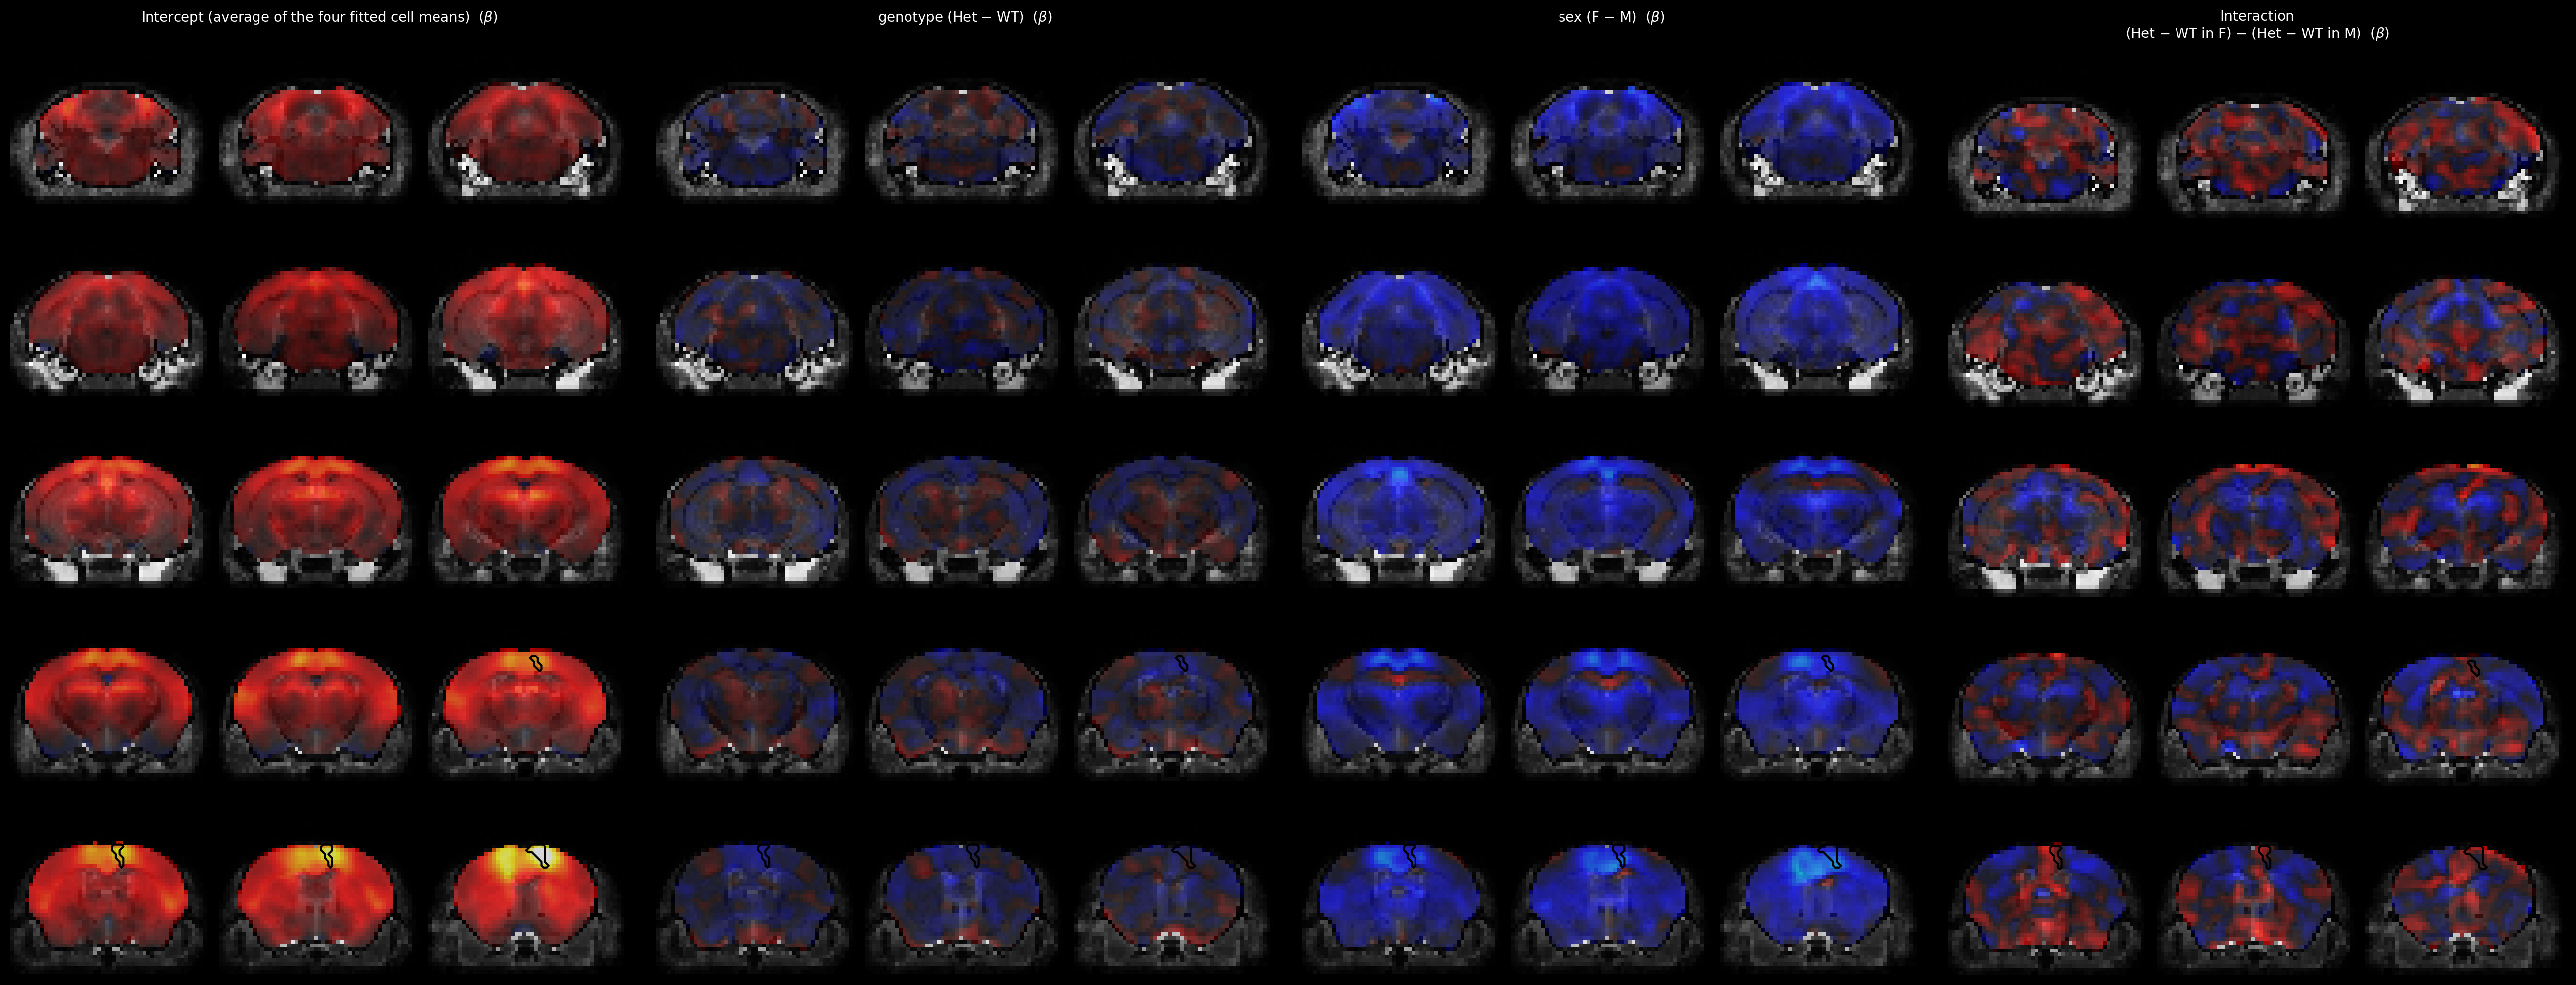

In [104]:
slice_ids = np.linspace(10, 25, 15).astype(int)
ncols = 3
nrows = (len(slice_ids) + ncols - 1) // ncols

g1, g2 = factor1_order
s1, s2 = factor2_order

panels = [
    ("intercept", "Intercept (average of the four fitted cell means)"),
    (factor1, f"{factor1} ({g1} − {g2})"),
    (factor2, f"{factor2} ({s1} − {s2})"),
    ("interaction", f"Interaction\n({g1} − {g2} in {s1}) − ({g1} − {g2} in {s2})"),
]

fig = plt.figure(
    figsize=(26, 10), dpi=200, facecolor="black", layout="constrained"
)
subfigs = fig.subfigures(1, len(panels), wspace=0.03)

for subfig, (key, title) in zip(subfigs, panels):
    axes = subfig.subplots(
        nrows, ncols, squeeze=False,
        gridspec_kw={"wspace": 0, "hspace": 0},
    )

    plot_img(
        lmm_effects[key]["estimate"],
        data_obj.brain_mask_file,
        template_path=str(template_path),
        seed_path=str(seed_path),
        slice_ids=slice_ids,
        cmap="cold_hot",
        vmin=-0.5,
        vmax=0.5,
        th=0,
        fig=subfig,
        ax=axes,
    )

    subfig.suptitle(title + r"  ($\beta$)", color="white", fontsize=10)

plt.show()

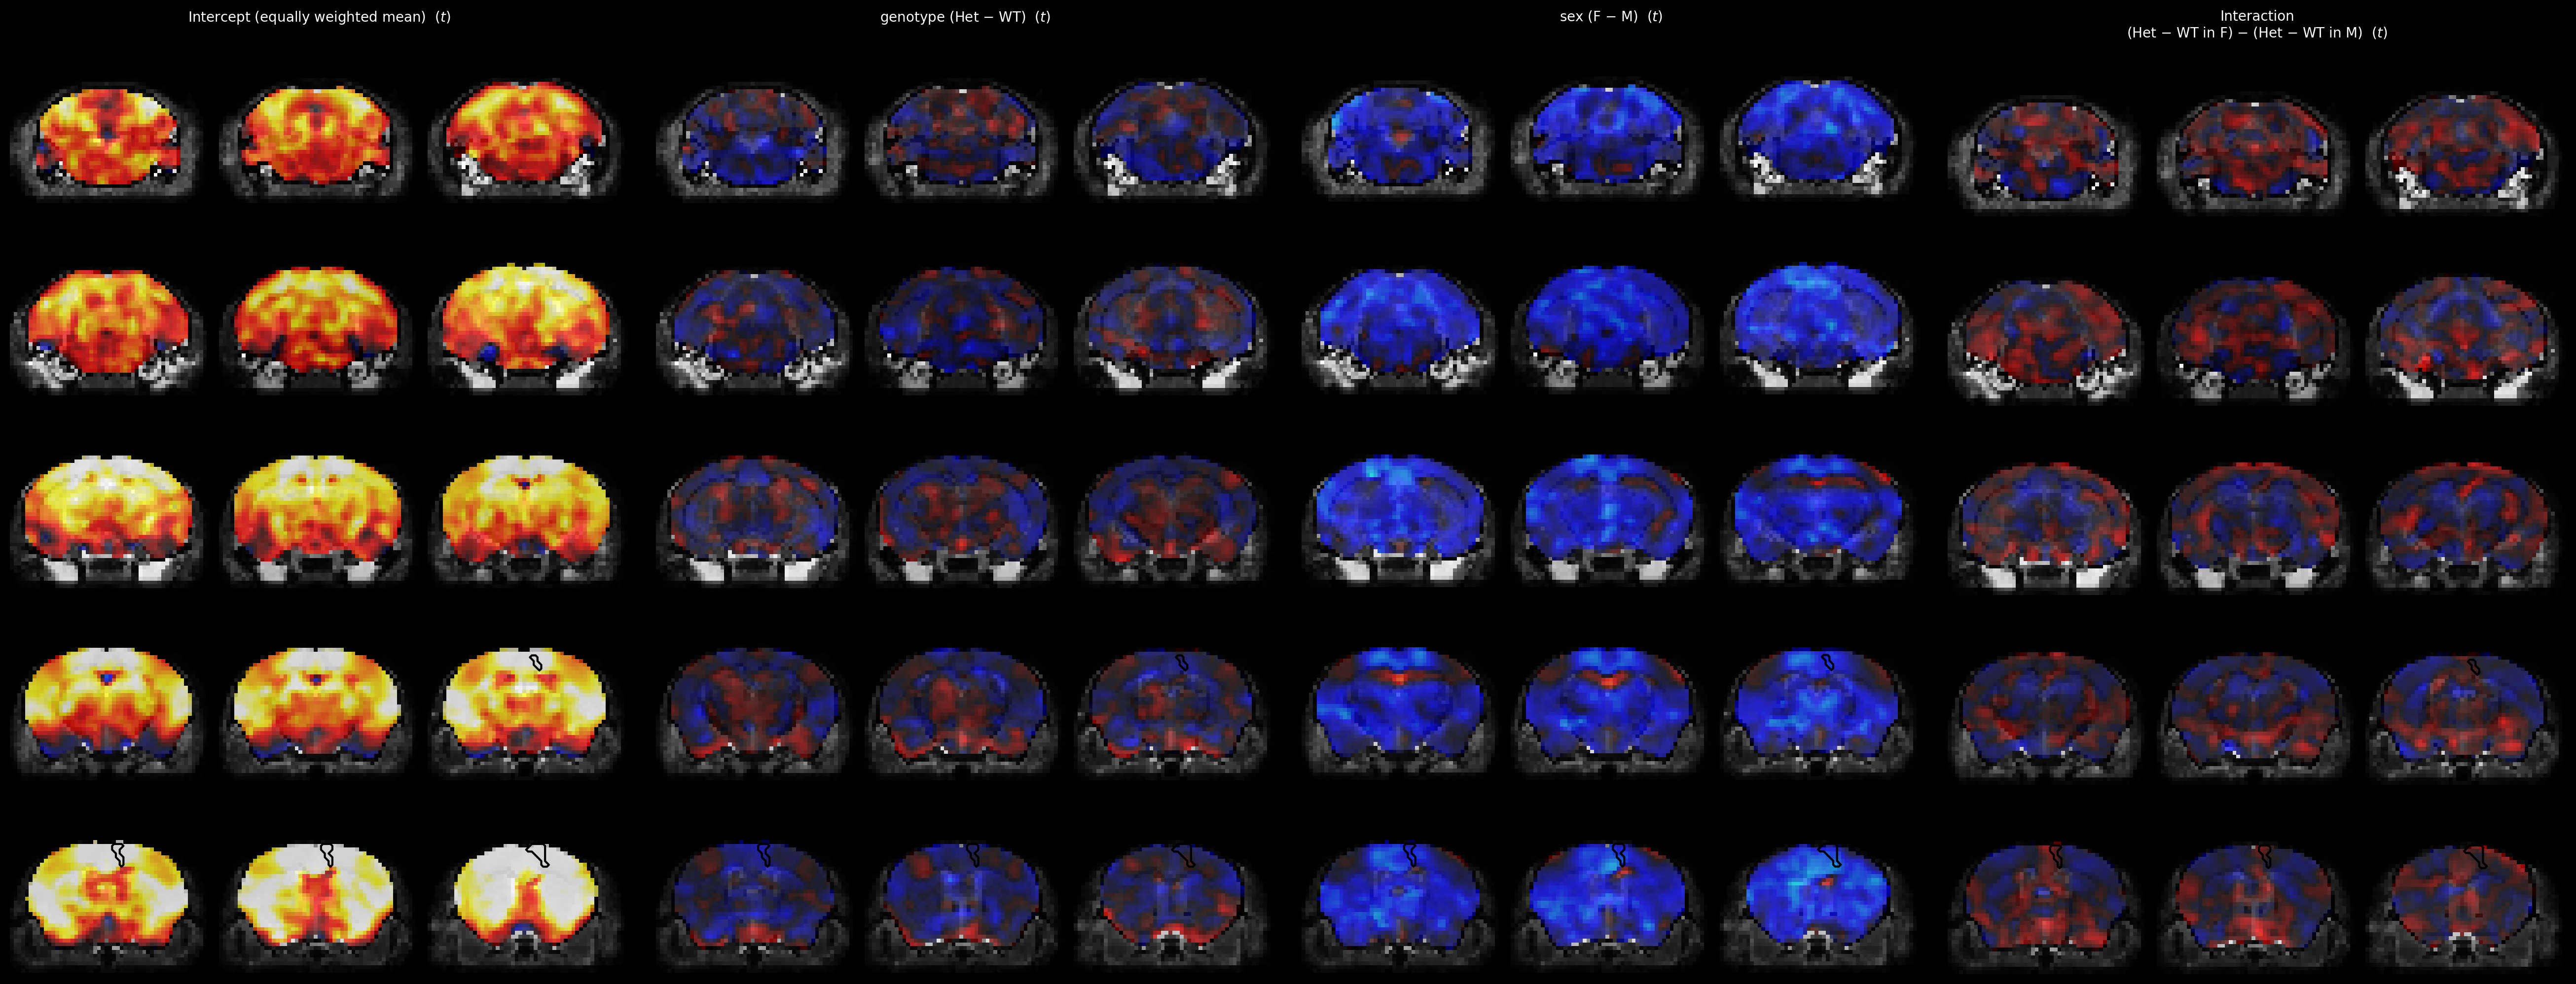

In [105]:
slice_ids = np.linspace(10, 25, 15).astype(int)
ncols = 3
nrows = (len(slice_ids) + ncols - 1) // ncols

g1, g2 = factor1_order
s1, s2 = factor2_order

panels = [
    ("intercept", "Intercept (equally weighted mean)"),
    (factor1, f"{factor1} ({g1} − {g2})"),
    (factor2, f"{factor2} ({s1} − {s2})"),
    ("interaction", f"Interaction\n({g1} − {g2} in {s1}) − ({g1} − {g2} in {s2})"),
]

fig_t = plt.figure(
    figsize=(26, 10), dpi=200, facecolor="black", layout="constrained"
)
subfigs_t = fig_t.subfigures(1, len(panels), wspace=0.03)

for subfig, (key, title) in zip(subfigs_t, panels):
    axes = subfig.subplots(
        nrows, ncols, squeeze=False,
        gridspec_kw={"wspace": 0, "hspace": 0},
    )

    plot_img(
        lmm_effects[key]["statistic"],
        data_obj.brain_mask_file,
        template_path=str(template_path),
        seed_path=str(seed_path),
        slice_ids=slice_ids,
        cmap="cold_hot",
        vmin=-8,
        vmax=8,
        th=0,
        fig=subfig,
        ax=axes,
    )

    subfig.suptitle(title + r"  ($t$)", color="white", fontsize=10)

plt.show()

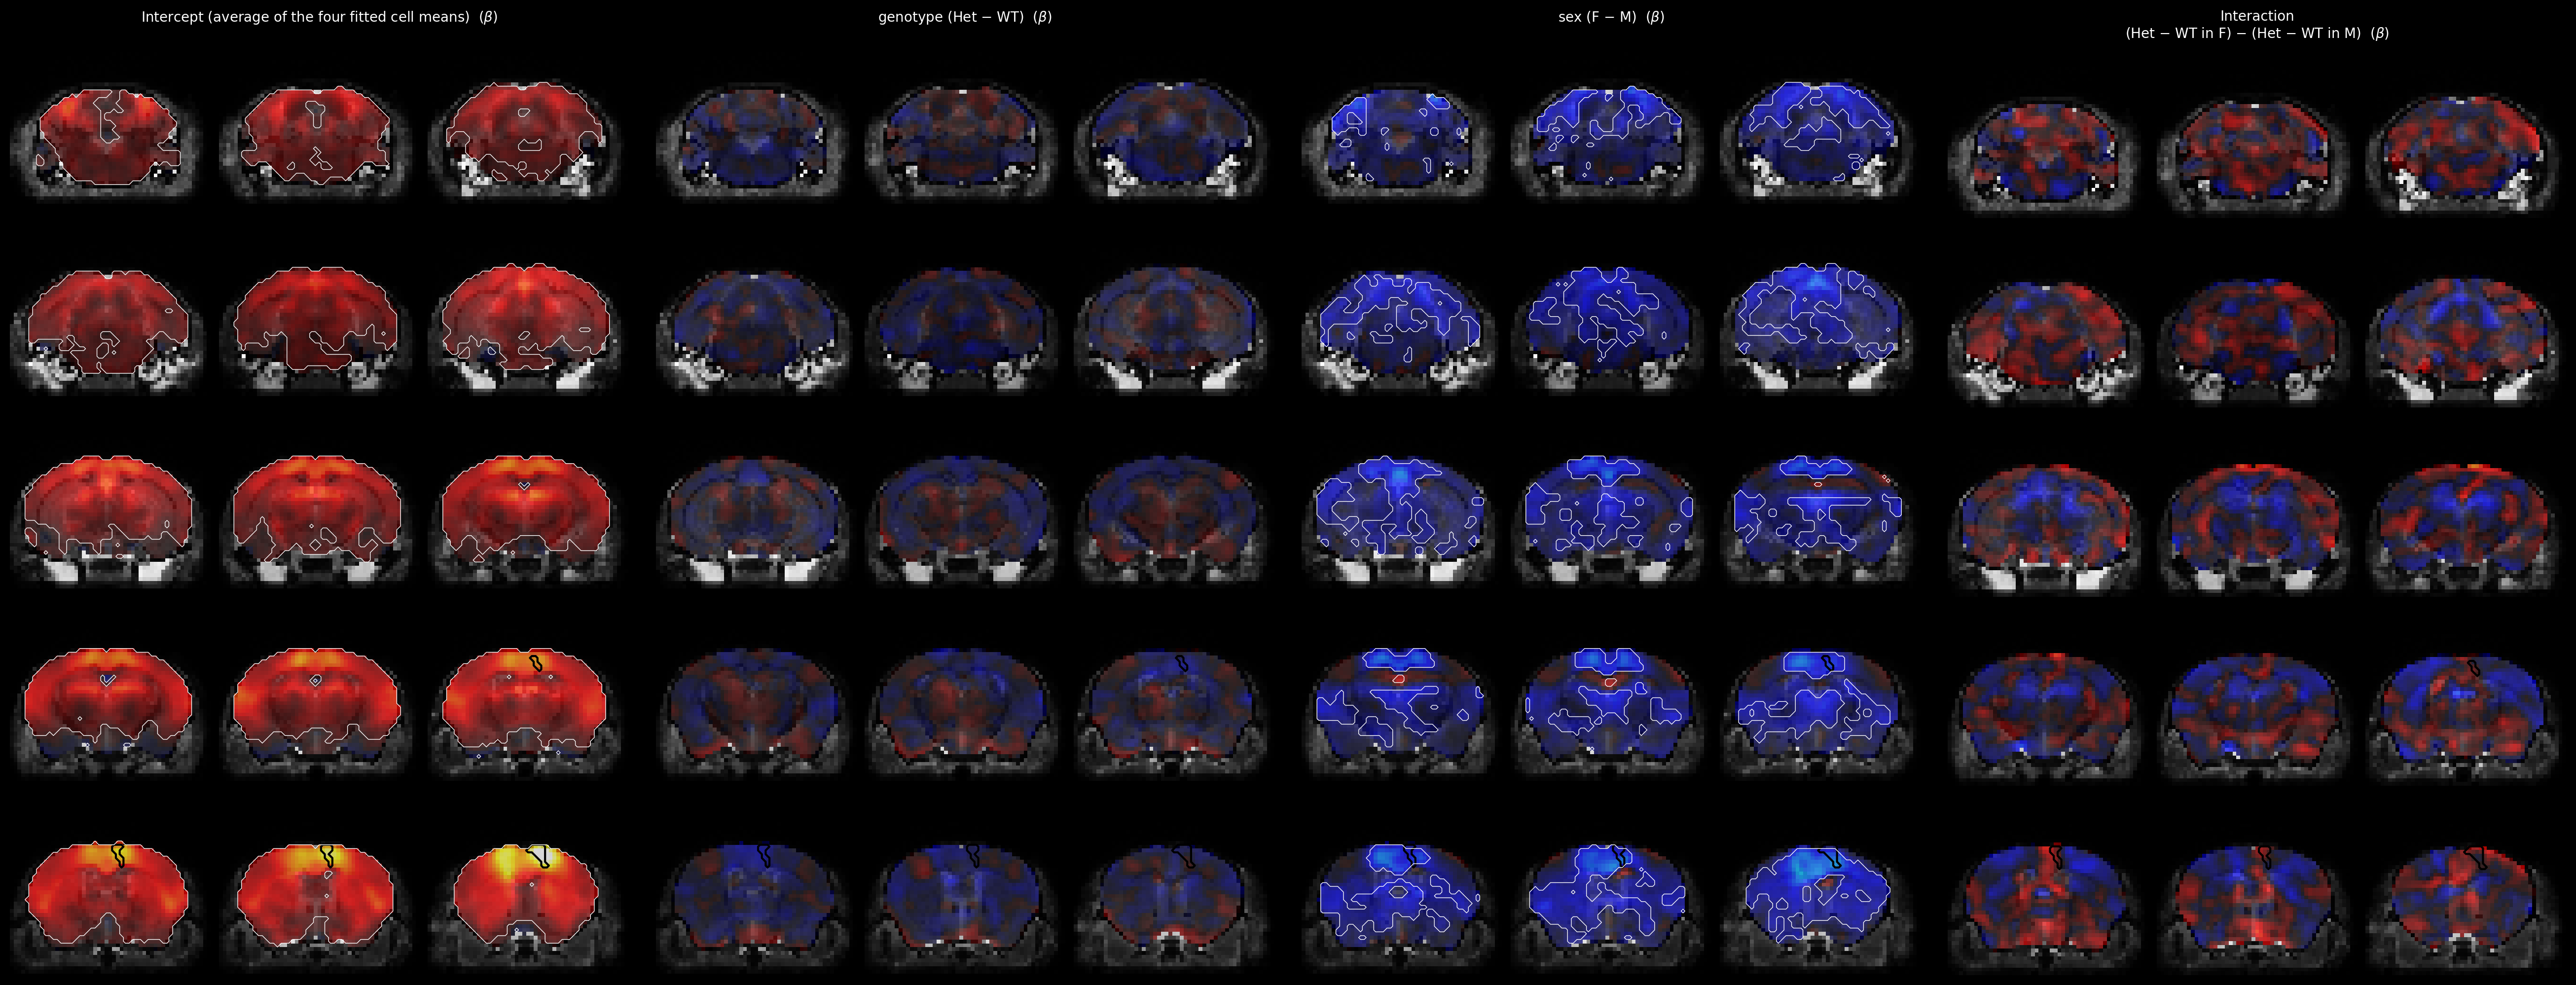

In [106]:
slice_ids = np.linspace(10, 25, 15).astype(int)
ncols = 3
nrows = (len(slice_ids) + ncols - 1) // ncols

g1, g2 = factor1_order
s1, s2 = factor2_order

panels = [
    ("intercept", "Intercept (average of the four fitted cell means)"),
    (factor1, f"{factor1} ({g1} − {g2})"),
    (factor2, f"{factor2} ({s1} − {s2})"),
    ("interaction", f"Interaction\n({g1} − {g2} in {s1}) − ({g1} − {g2} in {s2})"),
]

fig = plt.figure(
    figsize=(26, 10), dpi=200, facecolor="black", layout="constrained"
)
subfigs = fig.subfigures(1, len(panels), wspace=0.03)

for subfig, (key, title) in zip(subfigs, panels):
    axes = subfig.subplots(
        nrows, ncols, squeeze=False,
        gridspec_kw={"wspace": 0, "hspace": 0},
    )

    plot_img(
        lmm_effects[key]["estimate"],
        data_obj.brain_mask_file,
        template_path=str(template_path),
        seed_path=str(seed_path),
        slice_ids=slice_ids,
        cmap="cold_hot",
        vmin=-0.5,
        vmax=0.5,
        th=0,
        fig=subfig,
        ax=axes,
    )

    subfig.suptitle(title + r"  ($\beta$)", color="white", fontsize=10)

    reject = corrected[key]["fdr_bh"]["reject"]

    if reject.any():
        plot_add_contour(
            subfig,
            axes,
            reject.astype(float),
            data_obj.brain_mask_file,
            slice_ids=slice_ids,
            levels=(0.5,),
            colors=("white",),
            linestyles=("-",),
            linewidths=(0.5,),
        )

plt.show()

## Thresholded

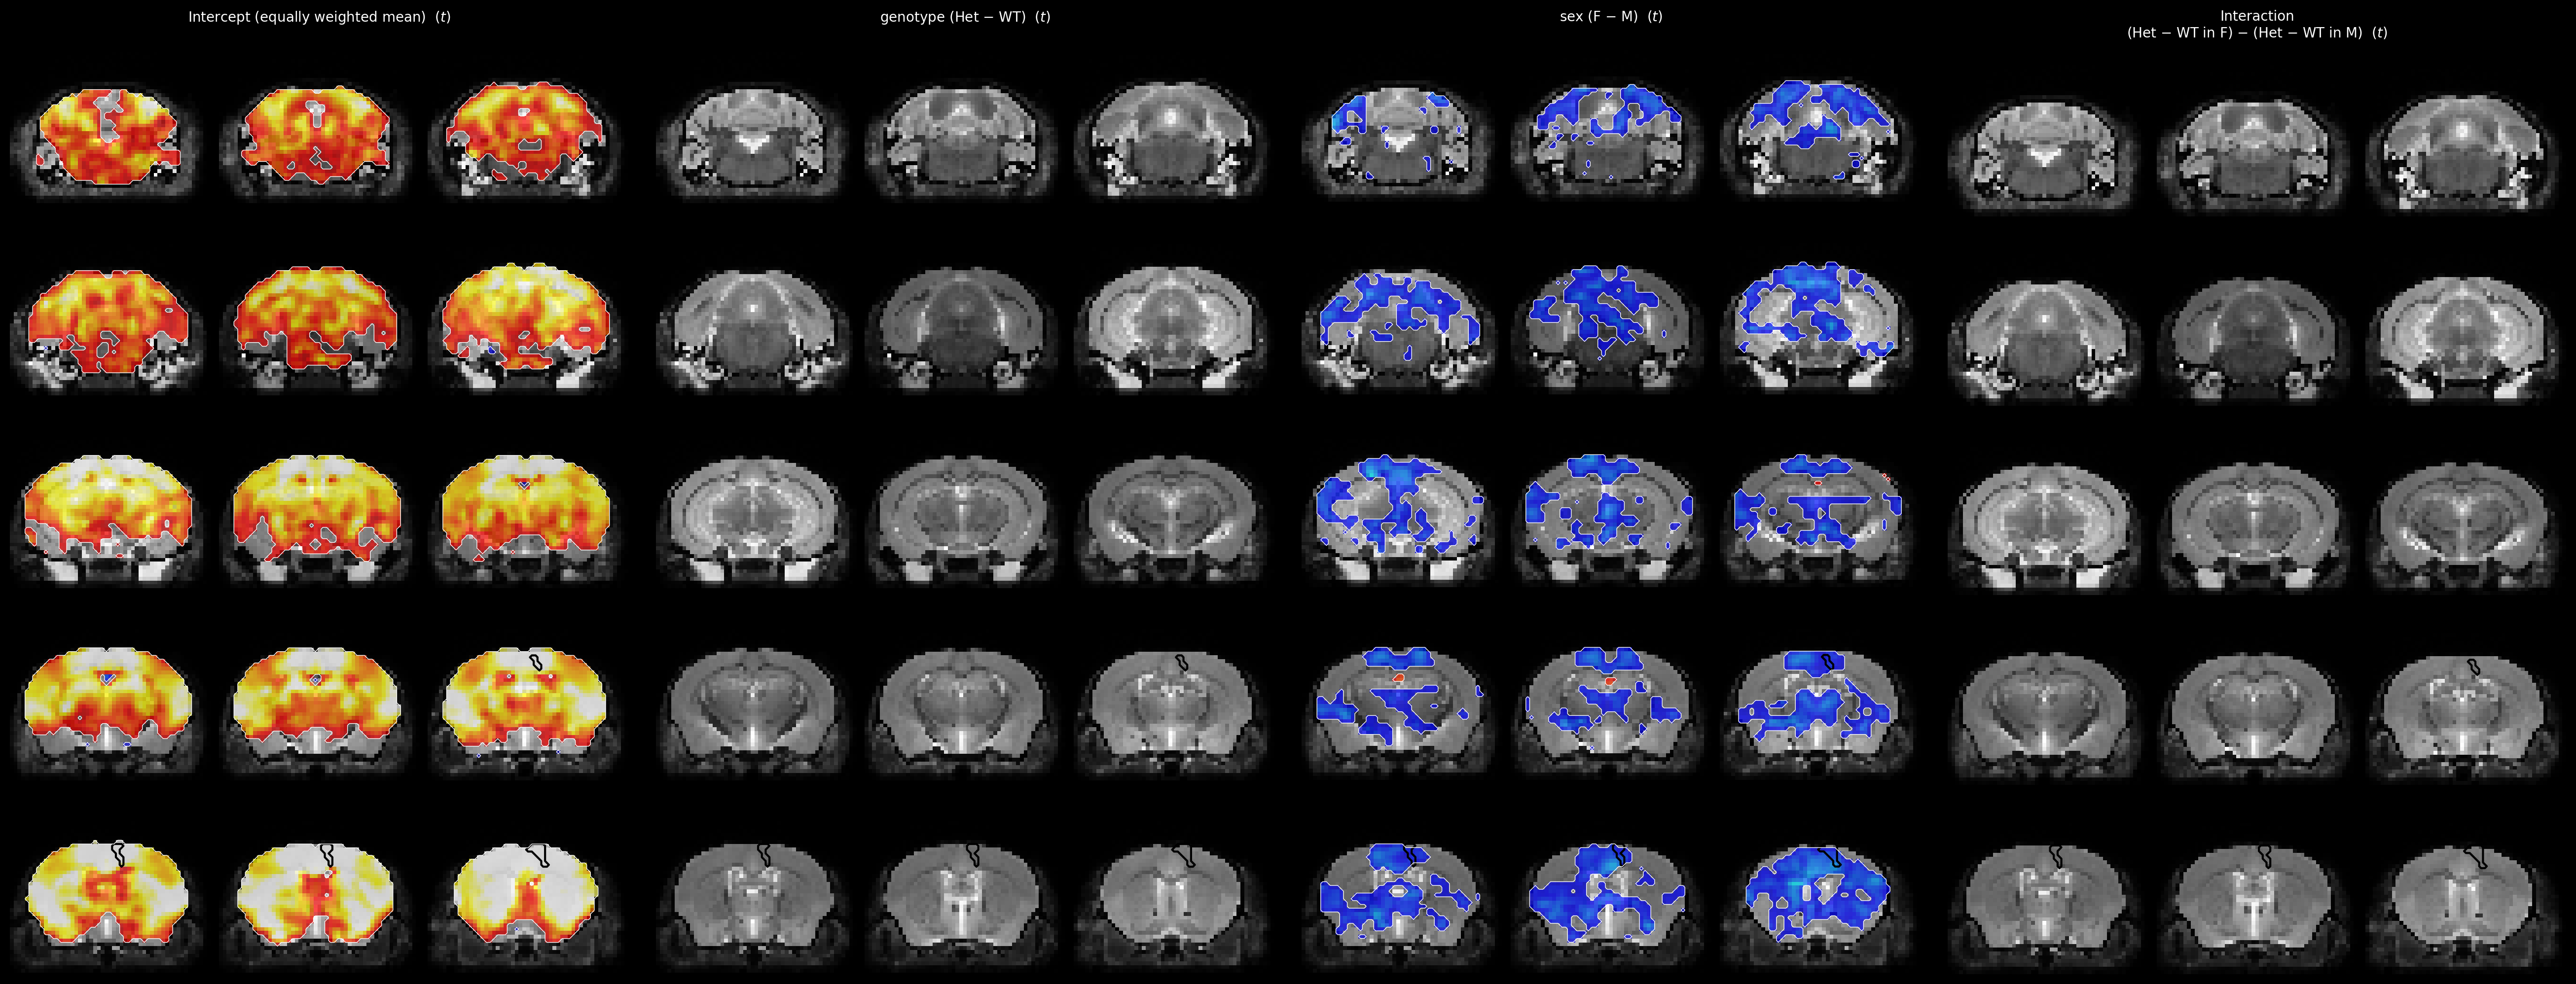

In [107]:
slice_ids = np.linspace(10, 25, 15).astype(int)
ncols = 3
nrows = (len(slice_ids) + ncols - 1) // ncols

g1, g2 = factor1_order
s1, s2 = factor2_order

panels = [
    ("intercept", "Intercept (equally weighted mean)"),
    (factor1, f"{factor1} ({g1} − {g2})"),
    (factor2, f"{factor2} ({s1} − {s2})"),
    ("interaction", f"Interaction\n({g1} − {g2} in {s1}) − ({g1} − {g2} in {s2})"),
]

fig_t = plt.figure(
    figsize=(26, 10), dpi=200, facecolor="black", layout="constrained"
)
subfigs_t = fig_t.subfigures(1, len(panels), wspace=0.03)

for subfig, (key, title) in zip(subfigs_t, panels):
    axes = subfig.subplots(
        nrows, ncols, squeeze=False,
        gridspec_kw={"wspace": 0, "hspace": 0},
    )

    
    reject = corrected[key]["fdr_bh"]["reject"]

    
    plot_img(
        lmm_effects[key]["statistic"],
        data_obj.brain_mask_file,
        template_path=str(template_path),
        seed_path=str(seed_path),
        slice_ids=slice_ids,
        cmap="cold_hot",
        vmin=-8,
        vmax=8,
        th=reject,
        fig=subfig,
        ax=axes,
    )

    if reject.any():
        plot_add_contour(
            subfig,
            axes,
            reject.astype(float),
            data_obj.brain_mask_file,
            slice_ids=slice_ids,
            levels=(0.5,),
            colors=("white",),
            linestyles=("-",),
            linewidths=(0.5,),
        )

    subfig.suptitle(title + r"  ($t$)", color="white", fontsize=10)

plt.show()

# End